# Whole-detector defect indicators and corrected diffraction patterns

Read-only analysis of scans **100207–100216**, described as identical scans of the same sample, and their saved corrections. Run from the top. No refitting or acquisition-file writes are performed.

0. **Introduce the problem directly:** compare the same raw frame from every scan, normalised only by its measured I0, with shared intensity scales and a fixed zoom.
1. **Bad pixels:** plot saved fit-outlier counts, fractions, and newly flagged/cleared counts versus scan number on a fixed eligible detector area.
2. **Wavy lines:** extract bright and dark ridge bands independently using fixed settings and detector support; plot whole-detector coverage and fragment counts and compare coverage against bad-pixel count.
3. **Corrected 1D data:** integrate every frame of every scan with its own saved correction on a common **2000-bin 2θ grid**, following the fast extraction workflow. Show a high-angle waterfall and a local discontinuity proxy versus scan number.
4. **Conclusions:** relate residual high-angle abruptness to the two detector-map indicators, with explicit limitations and a scale-sensitivity check.

The operational aim is to inform a **whole-detector reset strategy**, not rank sensors. Sensor boundaries are respected internally only to avoid filtering artefacts. This sequence contains no reset/recovery comparison or independently established acceptable-quality limit, so it cannot yet specify a reset trigger. Own-corrected source-scan integration is an in-sample check, not an independent calibration test.

Scan number is acquisition order, not dose or elapsed time. Threshold crossings can reflect strengthening contrast or changing noise/fit residuals rather than newly created physical defects. Associations are descriptive, not causal evidence.

Results stay in memory and notebook outputs; optional export is off by default. Candidates are not confirmed dead pixels or detector damage. The 1D integration takes about five minutes in the selected environment.

In [17]:
from pathlib import Path
import hashlib
import json
import warnings

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.ndimage import gaussian_filter, minimum_filter, label

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'eiger_workflow.py').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'eiger_workflow.py').is_file():
    raise FileNotFoundError('Start this notebook inside the eiger-correction repository.')
INPUT_DIRECTORY = ROOT / 'outputs/cross_analysis/ten_repeats_100207_100216_v1/calibrations'
SCANS = np.arange(100207, 100217)
RIDGE_SIGMA = 2.0       # One fixed spatial scale, in detector pixels.
RIDGE_BETA = 0.35       # Downweight round spots relative to lines.
RIDGE_THRESHOLD = 0.5   # Fixed absolute response threshold (log-% derived).
MIN_LINE_PIXELS = 20    # Minimum connected fragment area, NOT skeleton length.
TRUNCATE = 4.0
ZOOM_CENTRE = None      # Optional (row, column); None selects strongest retained ridge in last scan.
ZOOM_HALF_WIDTH = 40
EXPORT_RESULTS = False
EXPORT_DIRECTORY = ROOT / 'outputs/repeat_defects_100207_100216'

assert np.isfinite(RIDGE_SIGMA) and RIDGE_SIGMA >= 1
assert np.isfinite(RIDGE_BETA) and RIDGE_BETA > 0
assert np.isfinite(RIDGE_THRESHOLD) and RIDGE_THRESHOLD > 0
assert isinstance(MIN_LINE_PIXELS, int) and MIN_LINE_PIXELS >= 1
assert np.isfinite(TRUNCATE) and TRUNCATE >= 1
assert isinstance(ZOOM_HALF_WIDTH, int) and ZOOM_HALF_WIDTH >= 1
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.grid': False})
cmap = plt.get_cmap('RdBu_r').copy()
cmap.set_bad('0.8')
paths = [INPUT_DIRECTORY / f'{scan}_detector_corrections.h5' for scan in SCANS]
missing = [str(path) for path in paths if not path.is_file()]
if missing:
    raise FileNotFoundError('Missing expected repeat calibrations: ' + ', '.join(missing))
print(f'Using exactly {len(paths)} saved calibrations: {SCANS[0]}–{SCANS[-1]}')

Using exactly 10 saved calibrations: 100207–100216


In [18]:
# Load only saved correction products; never open source scans or refit.
def as_text(value):
    return value.decode() if isinstance(value, bytes) else str(value)


records, rows = [], []
for scan, path in zip(SCANS, paths):
    with h5py.File(path, 'r') as handle:
        group = handle['corrections']
        record = {key: group[key][()] for key in (
            'combined_divisor', 'bad_pixel_mask', 'base_mask', 'sensor_ids', 'observations')}
        settings = json.loads(as_text(handle.attrs['fit_settings_json']))
        minimum = int(settings.get('minimum_observations', 8))
        base = record['base_mask'].astype(bool)
        sensor = record['sensor_ids']
        supported = (record['observations'] >= minimum) & (sensor >= 0)
        positive = np.isfinite(record['combined_divisor']) & (record['combined_divisor'] > 0)
        record['eligible'] = ~base & supported
        record['flagged'] = record['bad_pixel_mask'].astype(bool) & record['eligible']
        record['valid'] = record['eligible'] & positive & ~record['bad_pixel_mask'].astype(bool)
        rows.append({'scan': int(scan), 'base_mask_pixels': int(base.sum()),
                     'insufficient_support_outside_base': int((~base & ~supported).sum()),
                     'flagged_outside_base': int((record['bad_pixel_mask'].astype(bool) & ~base).sum()),
                     'eligible_flagged': int(record['flagged'].sum()),
                     'valid_pixels': int(record['valid'].sum()), 'minimum_observations': minimum,
                     'geometry_hash': hashlib.sha256(as_text(handle['geometry_json'][()]).encode()).hexdigest()[:12],
                     'fit_settings': json.dumps(settings, sort_keys=True)})
    records.append(record)

sensor_ids = records[0]['sensor_ids']
for record in records:
    for key in ('combined_divisor', 'bad_pixel_mask', 'base_mask', 'observations'):
        if record[key].shape != sensor_ids.shape:
            raise ValueError(f'Incompatible detector shape for {key}.')
    np.testing.assert_array_equal(record['sensor_ids'], sensor_ids)
summary = pd.DataFrame(rows).set_index('scan')
for field in ('geometry_hash', 'fit_settings'):
    if summary[field].nunique(dropna=False) != 1:
        warnings.warn(f'{field} differs: repeat comparisons may include calibration differences.')
common_valid = np.logical_and.reduce([record['valid'] for record in records])
base_union = np.logical_or.reduce([record['base_mask'].astype(bool) for record in records])
if not common_valid.any():
    raise ValueError('No valid support shared by all ten maps.')
sensors = np.unique(sensor_ids[sensor_ids >= 0])
print(f'Detector: {sensor_ids.shape}; sensors: {len(sensors)}; common valid pixels: {common_valid.sum():,}')
display(summary.drop(columns='fit_settings'))

Detector: (512, 1028); sensors: 8; common valid pixels: 508,982


,base_mask_pixels,insufficient_support_outside_base,flagged_outside_base,eligible_flagged,valid_pixels,minimum_observations,geometry_hash
scan,,,,,,,
100207,17323,0,11,11,509002,8,c19b5f51780e
100208,17323,0,11,11,509002,8,c19b5f51780e
100209,17323,0,14,14,508999,8,c19b5f51780e
100210,17323,0,19,19,508994,8,c19b5f51780e
100211,17323,0,19,19,508994,8,c19b5f51780e
100212,17323,0,21,21,508992,8,c19b5f51780e
100213,17323,0,22,22,508991,8,c19b5f51780e
100214,17323,0,23,23,508990,8,c19b5f51780e
100215,17323,0,27,27,508986,8,c19b5f51780e


## 0. Start with the raw observations: the same frame in all ten scans

Read one detector frame from each acquisition **read-only**, and divide each pixel by the I0 recorded for that exact frame: $J_s(r,c)=C_s(r,c)/I0_s$. No learned detector divisor, fitted frame gain, background subtraction, smoothing, solid-angle or polarisation correction is applied. Detector coordinates are shown as stored, without reorientation.

The default is the middle frame index present in **all ten calibration fit selections**. Verify the source-scan provenance, full angle/I0 arrays against the saved diagnostics, selected angle agreement and geometry. No angle averaging or raw-frame aggregation is used. Change `RAW_FRAME_INDEX` to another common fitted index if required.

All panels use a fixed mask (union of the saved base masks and any invalid/saturated pixel in these ten selected frames); learned bad-pixel flags are **not** masked. Grey marks excluded pixels. Full-frame panels share pooled 1st–99.5th percentile intensity limits; the fixed illustrative zoom has its own pooled limits, again shared across all scans. Clipping is for display only. I0 is used as the recorded monitor value, not rescaled separately for each image. The ROI is a visual example, not the area used for defect prevalence.

This introduces changes visible before applying the extracted corrections. I0 normalisation alone does not remove sample changes, geometry effects, counting noise or other instrumental drift, and cannot establish a detector-reset threshold by itself.

Same raw frame index 86 (frame 87), tth ≈ 41.500028°; verified against calibration frame angles/I0 and fit indices.
Raw display support: 509,013 pixels. No learned divisor or fitted frame gain applied.


,frame_index_zero_based,tth_deg,i0
scan,,,
100207,86,41.500028,0.101852
100208,86,41.500028,0.101573
100209,86,41.500028,0.101136
100210,86,41.500028,0.101507
100211,86,41.500028,0.101805
100212,86,41.500028,0.102218
100213,86,41.500028,0.101232
100214,86,41.500028,0.102492
100215,86,41.500028,0.101105


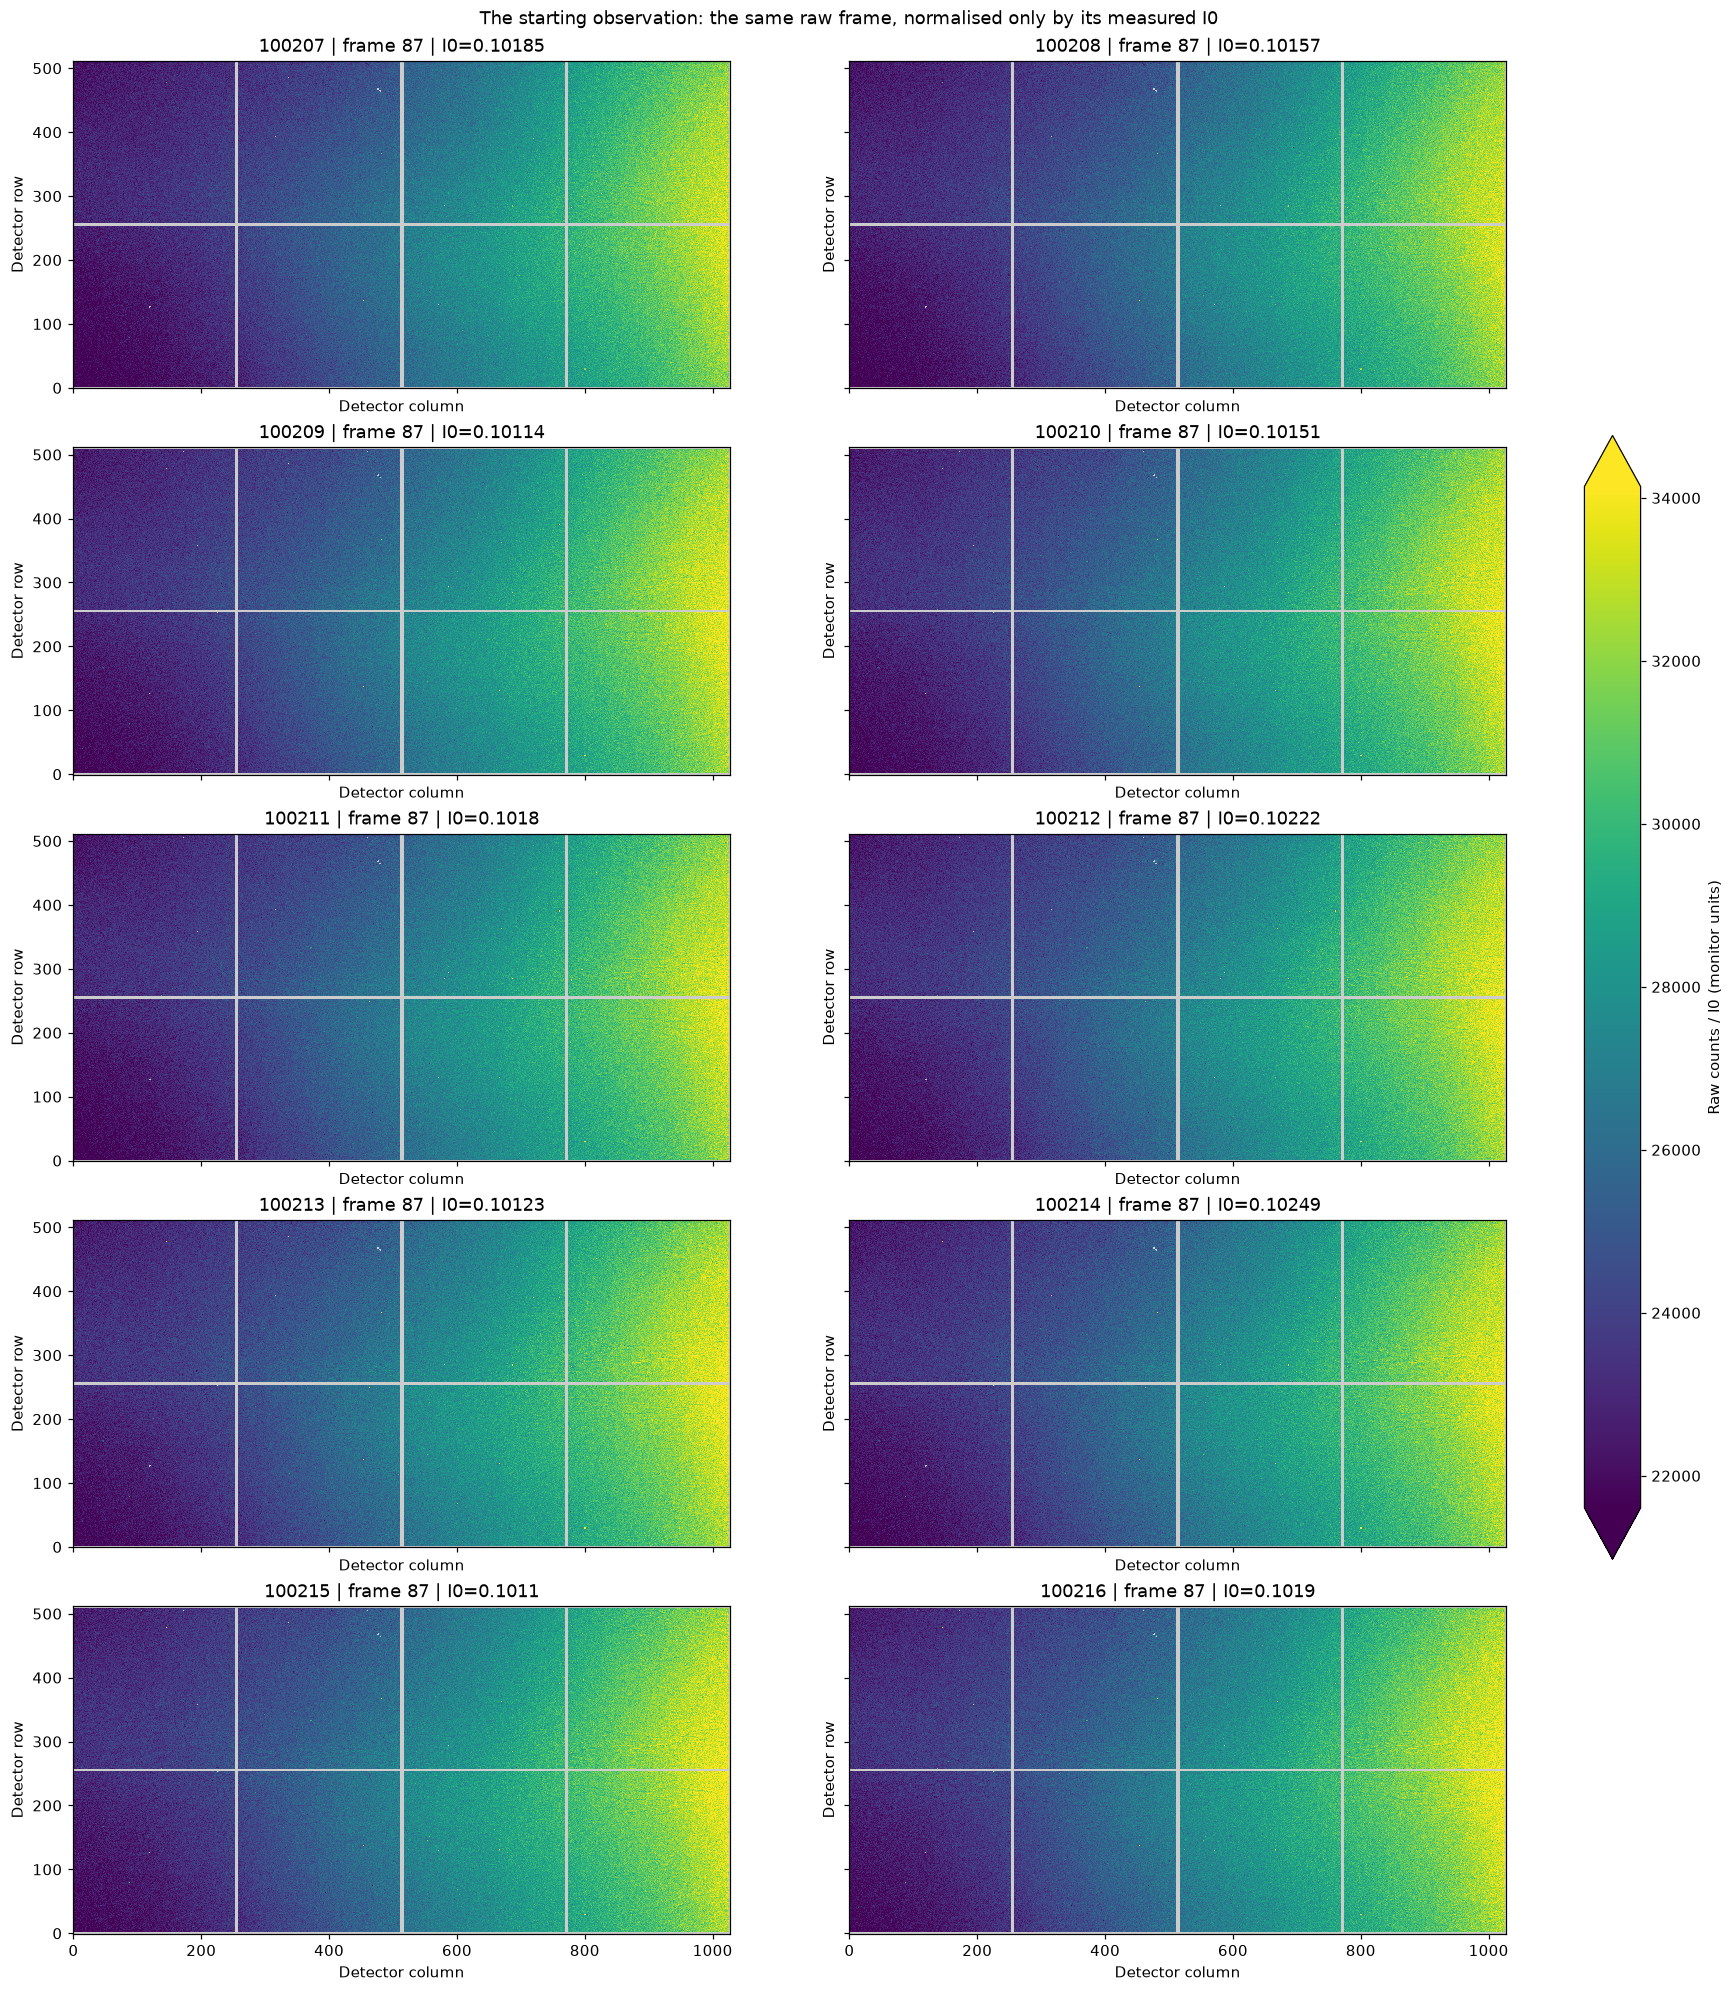

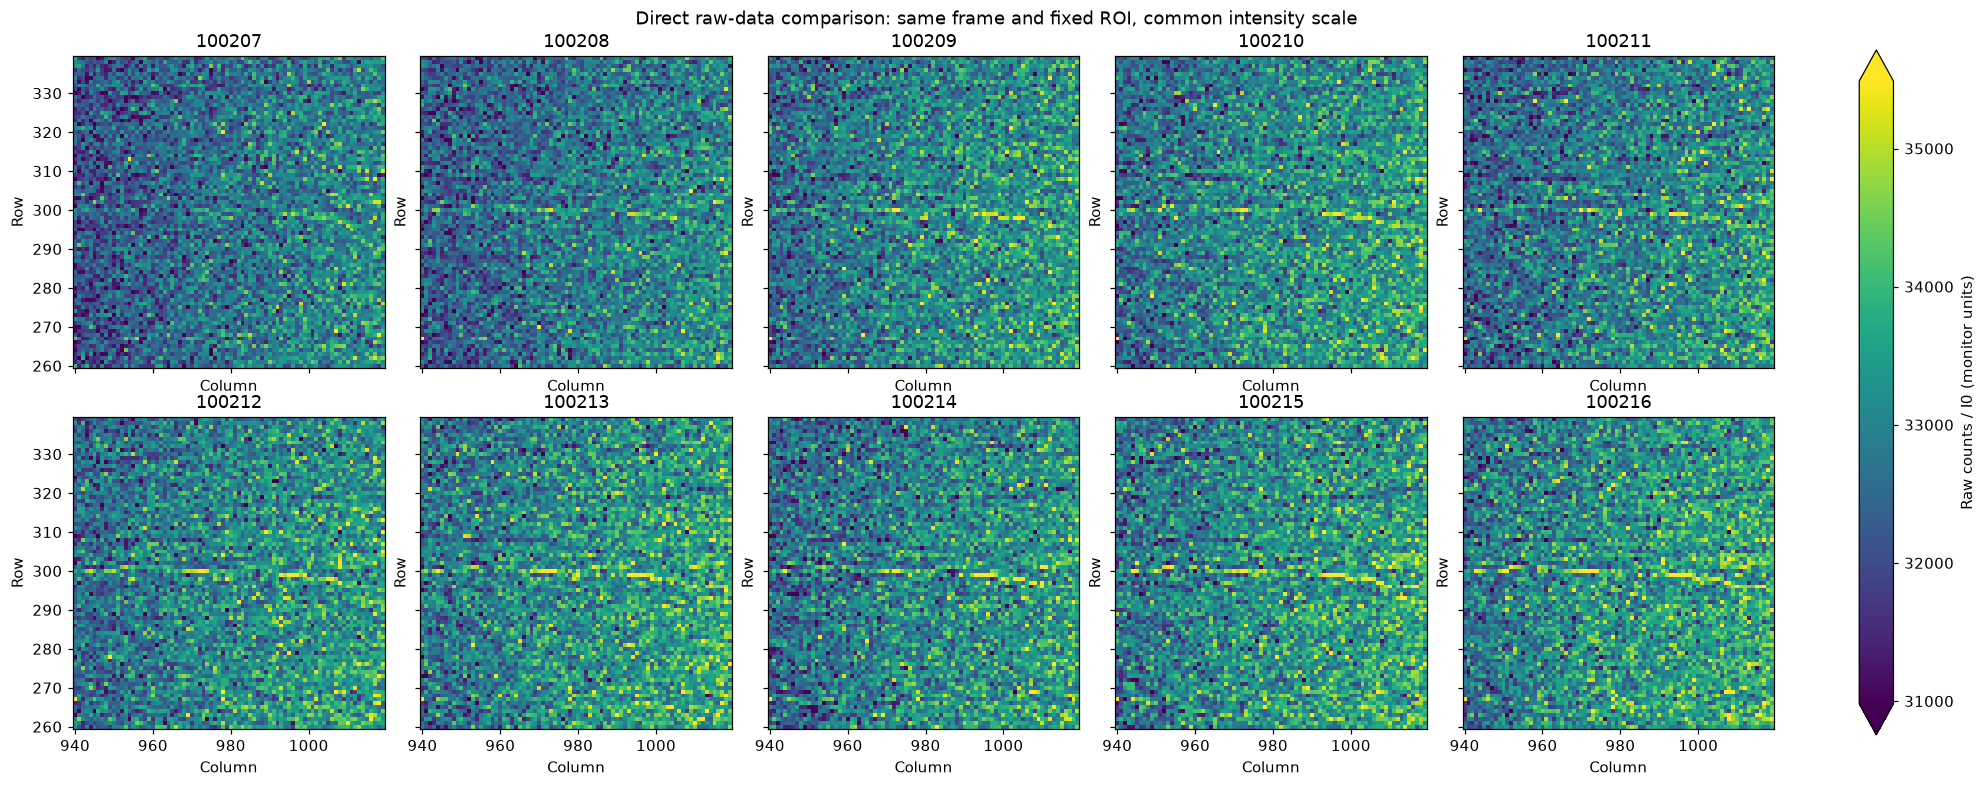

In [26]:
import hdf5plugin  # Registers raw-data compression filters; every acquisition file is read-only.
from matplotlib.colors import Normalize

RAW_DIRECTORY = Path('/dls/i15-1/data/2026/cm44163-4')
RAW_FRAME_INDEX = None  # Zero-based; None selects the middle index used in all ten fits.
RAW_ANGLE_TOLERANCE_DEG = 0.001
RAW_SATURATION = 1e7
RAW_ZOOM = (slice(260, 340), slice(940, 1020))  # Fixed illustrative ROI, not used for prevalence.

raw_sources, common_fit_indices = [], None
for scan, calibration_path in zip(SCANS, paths):
    nxs = RAW_DIRECTORY / f'i15-1-{scan}.nxs'
    with h5py.File(calibration_path, 'r') as calibration:
        if Path(as_text(calibration.attrs['source_scan'])).resolve() != nxs.resolve():
            raise ValueError(f'Calibration source does not match expected scan {scan}.')
        fit_indices = np.asarray(calibration['fit_diagnostics/fit_indices'][()], dtype=int).reshape(-1)
        fitted_angles = np.asarray(calibration['fit_diagnostics/frame_angles_deg'][()]).reshape(-1)
        fitted_i0 = np.asarray(calibration['fit_diagnostics/frame_i0'][()]).reshape(-1)
    common_fit_indices = fit_indices if common_fit_indices is None else np.intersect1d(common_fit_indices, fit_indices)
    with h5py.File(nxs, 'r') as acquisition:
        angles = np.asarray(acquisition['entry/fastcs_eiger/tth'][()], dtype=float).reshape(-1)
        geometry = json.loads(as_text(acquisition['entry/plan_metadata/geometry_calibration'][()]))
    detector_path = nxs.with_name(nxs.stem + '-fastcs_eiger_000001.h5')
    detector_dataset = 'data'
    if not detector_path.is_file():
        detector_path, detector_dataset = nxs, 'entry/fastcs_eiger/data'
    monitor_path = nxs.with_name(nxs.stem + '-i0.h5')
    with h5py.File(monitor_path, 'r') as monitor:
        i0 = np.asarray(monitor['entry/data/data'][()], dtype=float).reshape(-1)
    with h5py.File(detector_path, 'r') as detector:
        shape = detector[detector_dataset].shape
    if shape != (len(angles), *sensor_ids.shape) or len(i0) != len(angles):
        raise ValueError(f'Frame/angle/I0 lengths differ for scan {scan}.')
    # These calibrations must refer to the unaggregated frame sequence used here.
    np.testing.assert_allclose(angles, fitted_angles, rtol=0, atol=1e-8)
    np.testing.assert_allclose(i0, fitted_i0, rtol=1e-8, atol=0)
    raw_sources.append({'scan': int(scan), 'nexus': nxs, 'detector': detector_path,
                        'dataset': detector_dataset, 'monitor': monitor_path, 'angles': angles,
                        'i0': i0, 'geometry': geometry})
if common_fit_indices is None or not len(common_fit_indices):
    raise ValueError('No common raw-frame index used in all ten fits.')
raw_frame_index = int(common_fit_indices[len(common_fit_indices) // 2]) if RAW_FRAME_INDEX is None else int(RAW_FRAME_INDEX)
if raw_frame_index not in common_fit_indices:
    raise ValueError('Choose an index used in every fit (see common_fit_indices).')
selected_angles = np.array([source['angles'][raw_frame_index] for source in raw_sources])
if np.ptp(selected_angles) > RAW_ANGLE_TOLERANCE_DEG:
    raise ValueError('Same frame index has different angles across scans; do not compare unmatched frames.')
reference_geometry = json.dumps(raw_sources[0]['geometry'], sort_keys=True)
if any(json.dumps(source['geometry'], sort_keys=True) != reference_geometry for source in raw_sources):
    raise ValueError('Raw-frame geometry differs across scans; a direct pixel comparison needs review.')

raw_frames, raw_rows = [], []
for source in raw_sources:
    with h5py.File(source['detector'], 'r') as detector:
        frame = np.asarray(detector[source['dataset']][raw_frame_index], dtype=float)
    monitor_value = float(source['i0'][raw_frame_index])
    if not np.isfinite(monitor_value) or monitor_value <= 0:
        raise ValueError(f'Invalid selected-frame I0 in scan {source["scan"]}.')
    raw_frames.append(frame)
    raw_rows.append({'scan': source['scan'], 'frame_index_zero_based': raw_frame_index,
                     'tth_deg': float(source['angles'][raw_frame_index]), 'i0': monitor_value,
                     'nexus_path': str(source['nexus']), 'detector_path': str(source['detector']),
                     'detector_dataset': source['dataset'], 'monitor_path': str(source['monitor'])})
raw_frames = np.stack(raw_frames)
raw_frame_summary = pd.DataFrame(raw_rows).set_index('scan')
# Base masks only: keep learned bad candidates visible in this raw-data illustration.
raw_support = (~base_union & np.all(np.isfinite(raw_frames) & (raw_frames >= 0)
                                   & (raw_frames < RAW_SATURATION), axis=0))
if not raw_support.any():
    raise ValueError('No common valid raw-frame pixels.')
raw_normalised = raw_frames / raw_frame_summary['i0'].to_numpy()[:, None, None]
raw_normalised[:, ~raw_support] = np.nan
print(f'Same raw frame index {raw_frame_index} (frame {raw_frame_index + 1}), '
      f'tth ≈ {selected_angles.mean():.6f}°; verified against calibration frame angles/I0 and fit indices.')
print(f'Raw display support: {raw_support.sum():,} pixels. No learned divisor or fitted frame gain applied.')
display(raw_frame_summary[['frame_index_zero_based', 'tth_deg', 'i0']])

# Pooled limits and a single linear colour scale for every scan, no per-image scaling.
raw_vmin, raw_vmax = np.percentile(raw_normalised[:, raw_support], [1, 99.5])
if raw_vmax <= raw_vmin:
    raise ValueError('Selected raw frames have no display contrast.')
raw_norm = Normalize(vmin=raw_vmin, vmax=raw_vmax)
raw_full_cmap = plt.get_cmap('viridis').copy()
raw_full_cmap.set_bad('0.8')
raw_cmap = plt.get_cmap('viridis').copy()
raw_cmap.set_bad('0.8')
fig, axes = plt.subplots(5, 2, figsize=(16, 18), constrained_layout=True, sharex=True, sharey=True)
for i, ax in enumerate(axes.flat):
    image = ax.imshow(np.ma.masked_invalid(raw_normalised[i]), origin='lower', cmap=raw_full_cmap,
                      norm=raw_norm, interpolation='nearest')
    ax.set(title=f'{SCANS[i]} | frame {raw_frame_index + 1} | I0={raw_frame_summary.iloc[i].i0:.5g}',
           xlabel='Detector column', ylabel='Detector row')
fig.colorbar(image, ax=axes.ravel().tolist(), label='Raw counts / I0 (monitor units)', extend='both', shrink=0.6)
fig.suptitle('The starting observation: the same raw frame, normalised only by its measured I0')
plt.show()

# Identical ROI and intensity limits make subtle line changes easier to see.
raw_extent = (RAW_ZOOM[1].start - 0.5, RAW_ZOOM[1].stop - 0.5,
              RAW_ZOOM[0].start - 0.5, RAW_ZOOM[0].stop - 0.5)
roi_values = raw_normalised[(slice(None), *RAW_ZOOM)]
finite_roi = roi_values[np.isfinite(roi_values)]
if not finite_roi.size:
    raise ValueError('The selected raw zoom contains no valid pixels.')
roi_vmin, roi_vmax = np.percentile(finite_roi, [1, 99.5])
roi_norm = Normalize(vmin=roi_vmin, vmax=roi_vmax)
fig, axes = plt.subplots(2, 5, figsize=(18, 7), constrained_layout=True, sharex=True, sharey=True)
for i, ax in enumerate(axes.flat):
    image = ax.imshow(np.ma.masked_invalid(roi_values[i]), origin='lower', extent=raw_extent,
                      cmap=raw_cmap, norm=roi_norm, interpolation='nearest')
    ax.set(title=str(SCANS[i]), xlabel='Column', ylabel='Row')
fig.colorbar(image, ax=axes.ravel().tolist(), label='Raw counts / I0 (monitor units)', extend='both')
fig.suptitle('Direct raw-data comparison: same frame and fixed ROI, common intensity scale')
plt.show()

## 1. Whole-detector bad-pixel prevalence versus scan number

Use the saved `bad_pixel_mask`, not a new divisor threshold. Counts and fractions use the **intersection of eligible pixels across all ten scans** (outside base masks, sufficient observations, valid detector area). Crucially, eligibility does **not** exclude fit-outlier flags: those flags are what we count. This keeps the denominator fixed without removing newly flagged pixels.

New and cleared flags compare successive scans on that same area. Flags are fit-outlier candidates, not confirmed dead pixels; insufficient support and base masks remain separate in the input summary. All reported measures describe the overall detector, not sensor-number subsets.

Fixed bad-pixel denominator: 509,013 eligible pixels


,bad_fixed_count,bad_fixed_percent,new_flags,cleared_flags
scan,,,,
100207,11,0.002161,NaN,NaN
100208,11,0.002161,0.0,0.0
100209,14,0.002750,3.0,0.0
100210,19,0.003733,5.0,0.0
100211,19,0.003733,0.0,0.0
100212,21,0.004126,2.0,0.0
100213,22,0.004322,1.0,0.0
100214,23,0.004519,2.0,1.0
100215,27,0.005304,4.0,0.0


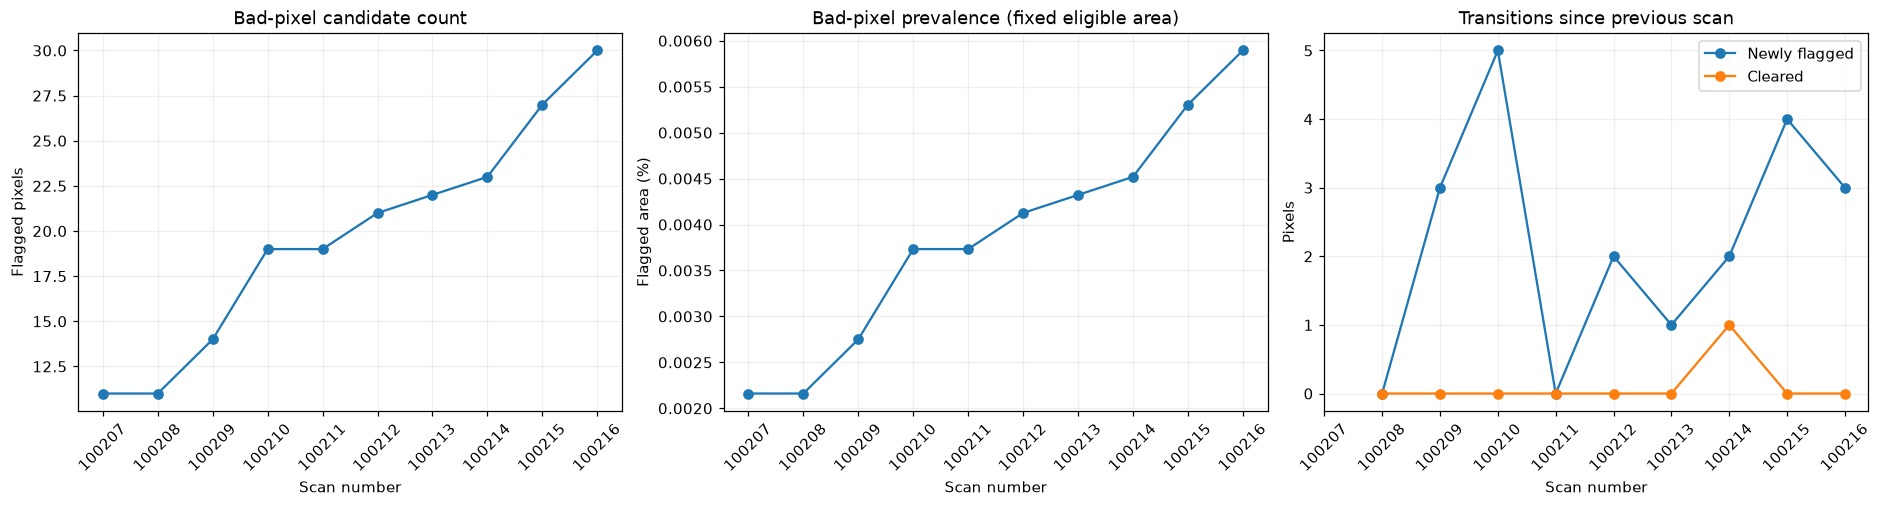

In [20]:
eligible_stack = np.stack([r['eligible'] for r in records])
bad_stack = np.stack([r['flagged'] for r in records])
bad_support = eligible_stack.all(axis=0)
if not bad_support.any():
    raise ValueError('No common eligible area for bad-pixel prevalence.')
fixed_bad = bad_stack & bad_support[None, :, :]
summary['bad_fixed_count'] = fixed_bad.sum(axis=(1, 2))
summary['bad_fixed_percent'] = 100 * summary['bad_fixed_count'] / bad_support.sum()
new_flags = np.full(len(SCANS), np.nan)
cleared_flags = new_flags.copy()
for i in range(1, len(SCANS)):
    new_flags[i] = np.count_nonzero(fixed_bad[i] & ~fixed_bad[i - 1])
    cleared_flags[i] = np.count_nonzero(~fixed_bad[i] & fixed_bad[i - 1])
summary['new_flags'] = new_flags
summary['cleared_flags'] = cleared_flags
rr, cc = np.where(fixed_bad.any(axis=0))
bad_pixels = pd.DataFrame({'row': rr, 'column': cc})
for i, scan in enumerate(SCANS):
    bad_pixels[f'flag_{scan}'] = fixed_bad[i, rr, cc]
print(f'Fixed bad-pixel denominator: {bad_support.sum():,} eligible pixels')
display(summary[['bad_fixed_count', 'bad_fixed_percent', 'new_flags', 'cleared_flags']])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), constrained_layout=True)
axes[0].plot(SCANS, summary['bad_fixed_count'], 'o-')
axes[0].set(title='Bad-pixel candidate count', ylabel='Flagged pixels')
axes[1].plot(SCANS, summary['bad_fixed_percent'], 'o-')
axes[1].set(title='Bad-pixel prevalence (fixed eligible area)', ylabel='Flagged area (%)')
axes[2].plot(SCANS, new_flags, 'o-', label='Newly flagged')
axes[2].plot(SCANS, cleared_flags, 'o-', label='Cleared')
axes[2].set(title='Transitions since previous scan', ylabel='Pixels')
axes[2].legend()
for ax in axes:
    ax.set_xlabel('Scan number')
    ax.set_xticks(SCANS)
    ax.ticklabel_format(axis='x', style='plain', useOffset=False)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(alpha=0.2)
plt.show()

## 2. Wavy-line prevalence: independent per-scan extraction

Use `100 × log(combined_divisor)` (approximately percent near unity), median-centred within each sensor and scan. Apply one Gaussian Hessian filter at `RIDGE_SIGMA = 2` pixels to **each scan separately**. Its larger-magnitude eigenvalue gives transverse curvature; an eigenvalue-ratio weight suppresses round spots. Negative curvature identifies bright divisor ridges, positive curvature dark ridges. Divisors act by division, so these labels are not raw-count polarities.

Use the same absolute response threshold and minimum 8-connected fragment area for every scan, without per-scan percentile thresholds or response normalisation. Bright/dark fragments and sensor IDs are labelled separately. The response is in log-percent-derived units, not a significance or calibrated amplitude.

The fixed ridge support is the common valid, non-flagged area, eroded by the full Gaussian radius within each sensor. This prevents changing masks or sensor edges from generating an apparent prevalence trend, but deliberately excludes all ever-invalid/flagged pixels and their margins: **ridge prevalence describes this fixed analysable area, not the entire detector**. Bad pixels are analysed separately above.

Primary measure: **retained ridge-band area / fixed ridge support**. Also report bright/dark coverage and fragment counts. Bands have width: area is not skeleton length, and connected fragments are not necessarily individual physical defects. Fragment counts may decrease when bands merge. Noise, fit residuals, contrast changes and threshold crossings can alter all these measures.

In [21]:
log_maps = np.full((len(SCANS), *sensor_ids.shape), np.nan, dtype=np.float64)
sensor_regions = []
ridge_support = np.zeros(sensor_ids.shape, dtype=bool)
radius = int(TRUNCATE * RIDGE_SIGMA + 0.5)
for sensor in sensors:
    rows_s, cols_s = np.where(sensor_ids == sensor)
    region = np.s_[rows_s.min():rows_s.max() + 1, cols_s.min():cols_s.max() + 1]
    local_valid = common_valid[region] & (sensor_ids[region] == sensor)
    safe = minimum_filter(local_valid.astype(np.uint8), size=2 * radius + 1,
                          mode='constant', cval=0).astype(bool)
    ridge_support[region] |= safe
    sensor_regions.append((region, local_valid, safe))
    if not local_valid.any():
        continue
    for i, record in enumerate(records):
        values = 100 * np.log(record['combined_divisor'][region][local_valid])
        log_maps[i][region][local_valid] = values - np.median(values)
if not ridge_support.any():
    raise ValueError('No ridge support remains after the filter-radius exclusion.')


def ridge_response(image):
    response = np.full(image.shape, np.nan)
    for region, valid, safe in sensor_regions:
        values = np.where(valid, image[region], 0.0)
        yy = gaussian_filter(values, RIDGE_SIGMA, order=(2, 0), mode='constant', truncate=TRUNCATE)
        xx = gaussian_filter(values, RIDGE_SIGMA, order=(0, 2), mode='constant', truncate=TRUNCATE)
        xy = gaussian_filter(values, RIDGE_SIGMA, order=(1, 1), mode='constant', truncate=TRUNCATE)
        root = np.sqrt((xx - yy)**2 + 4 * xy**2)
        eig_a, eig_b = 0.5 * (xx + yy - root), 0.5 * (xx + yy + root)
        large = np.where(np.abs(eig_a) >= np.abs(eig_b), eig_a, eig_b)
        small = np.where(np.abs(eig_a) >= np.abs(eig_b), eig_b, eig_a)
        ratio = np.divide(small, large, out=np.zeros_like(small), where=np.abs(large) > 1e-12)
        signed = -RIDGE_SIGMA**2 * large * np.exp(-ratio**2 / (2 * RIDGE_BETA**2))
        response[region][safe] = signed[safe]
    return response


def extract_fragments(response):
    output = np.zeros(sensor_ids.shape, dtype=np.int32)
    rows_out, next_id = [], 0
    for region, _, safe in sensor_regions:
        for polarity, sign in (('bright', 1), ('dark', -1)):
            components, _ = label(safe & (sign * response[region] >= RIDGE_THRESHOLD),
                                   structure=np.ones((3, 3), dtype=int))
            sizes = np.bincount(components.ravel())
            for component in np.flatnonzero(sizes[1:] >= MIN_LINE_PIXELS) + 1:
                local_rows, local_cols = np.where(components == component)
                rr = local_rows + region[0].start
                cc = local_cols + region[1].start
                next_id += 1
                output[rr, cc] = next_id
                rows_out.append({'fragment': next_id, 'polarity': polarity,
                                 'area_pixels': len(rr), 'row_min': rr.min(), 'row_max': rr.max(),
                                 'column_min': cc.min(), 'column_max': cc.max(),
                                 'peak_response': np.max(np.abs(response[rr, cc]))})
    columns = ['fragment', 'polarity', 'area_pixels', 'row_min', 'row_max',
               'column_min', 'column_max', 'peak_response']
    return output, pd.DataFrame(rows_out, columns=columns)


repeat_responses = np.stack([ridge_response(image) for image in log_maps])
labels_list, fragment_tables = [], []
for scan, response in zip(SCANS, repeat_responses):
    labels_scan, table = extract_fragments(response)
    table.insert(0, 'scan', int(scan))
    labels_list.append(labels_scan)
    fragment_tables.append(table)
repeat_labels = np.stack(labels_list)
repeat_line_masks = repeat_labels > 0
fragments = pd.concat(fragment_tables, ignore_index=True)
assert np.all(~repeat_line_masks | ridge_support[None, :, :])
assert np.all(np.isfinite(repeat_responses[:, ridge_support]))
print(f'Fixed ridge denominator after {radius}-pixel margins: {ridge_support.sum():,} pixels')
print('Each scan is extracted independently; no repeat-average or recurrence selection.')

Fixed ridge denominator after 8-pixel margins: 437,140 pixels
Each scan is extracted independently; no repeat-average or recurrence selection.


,bad_fixed_count,bad_fixed_percent,new_flags,cleared_flags,ridge_area_pixels,ridge_area_percent,bright_area_percent,dark_area_percent,fragment_count,bright_fragments,dark_fragments,median_fragment_area
scan,,,,,,,,,,,,
100207,11,0.00216,NaN,NaN,73,0.01670,0.01098,0.00572,3,2,1,24.0
100208,11,0.00216,0.0,0.0,122,0.02791,0.02105,0.00686,4,3,1,30.5
100209,14,0.00275,3.0,0.0,89,0.02036,0.00869,0.01167,3,1,2,28.0
100210,19,0.00373,5.0,0.0,208,0.04758,0.02493,0.02265,8,4,4,24.0
100211,19,0.00373,0.0,0.0,355,0.08121,0.04484,0.03637,14,8,6,25.0
100212,21,0.00413,2.0,0.0,604,0.13817,0.06062,0.07755,22,9,13,22.5
100213,22,0.00432,1.0,0.0,892,0.20405,0.09196,0.11209,35,15,20,24.0
100214,23,0.00452,2.0,1.0,1055,0.24134,0.11438,0.12696,38,18,20,24.5
100215,27,0.00530,4.0,0.0,1359,0.31088,0.14366,0.16722,51,23,28,24.0


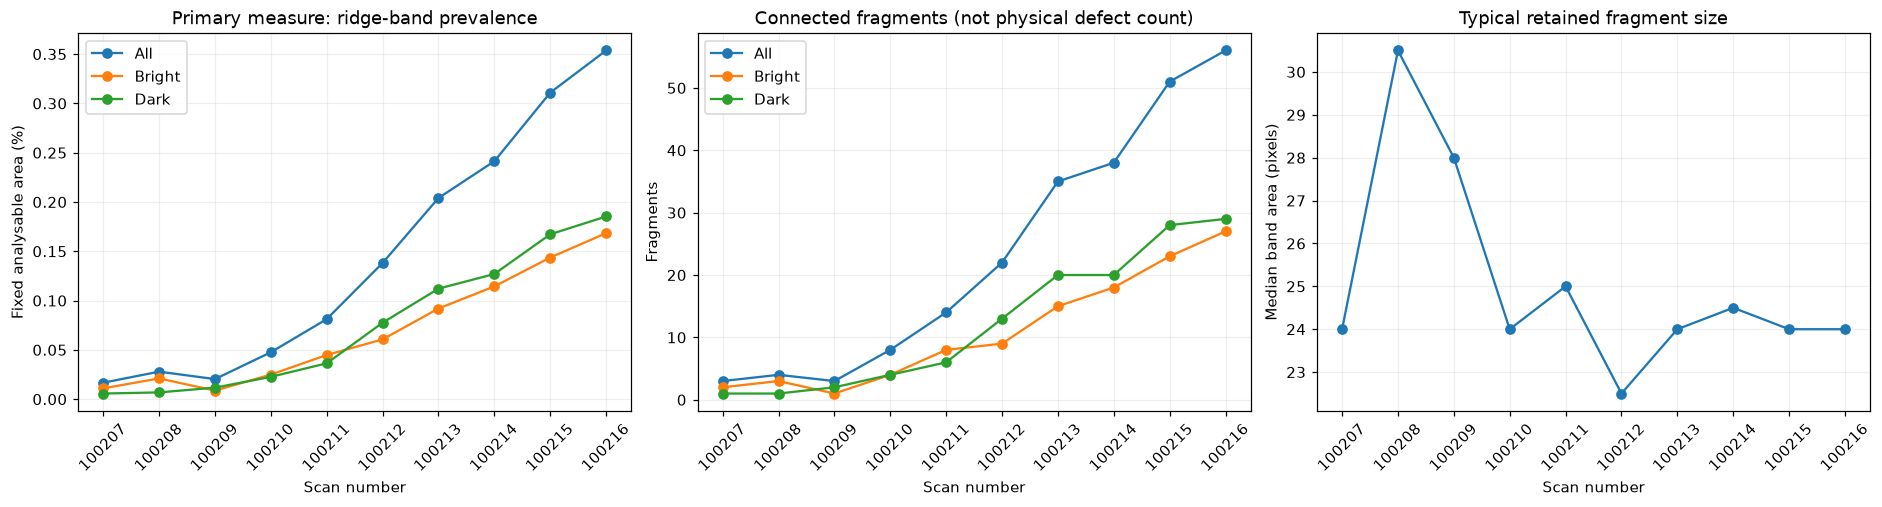

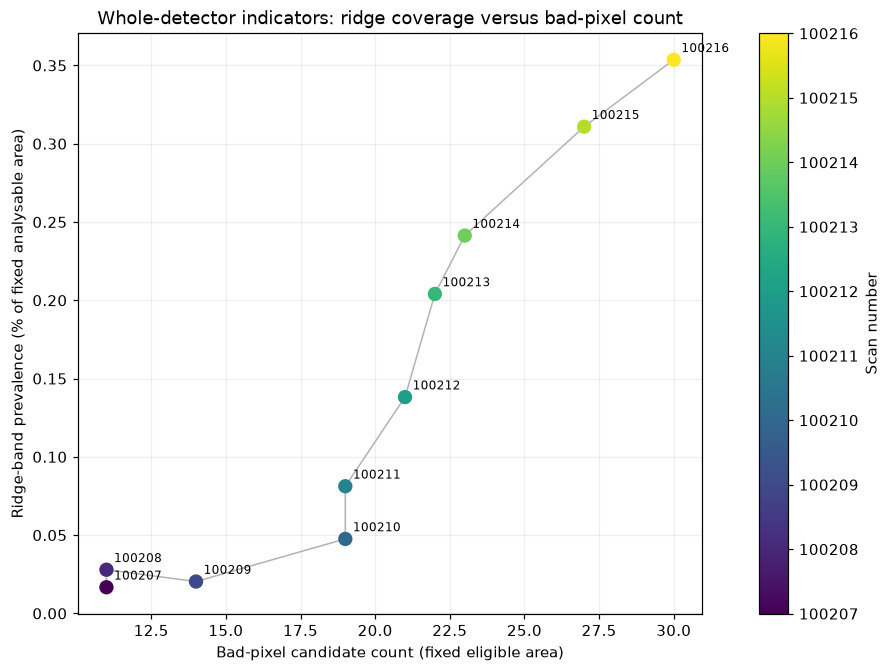

Bad candidates: 11 → 30 pixels.
Ridge-band area: 73 → 1546 pixels; fragments: 3 → 56.
The cross-plot is descriptive: both indicators share scan order; it is not an independent causal test or reset threshold.


In [22]:
prevalence_rows = []
for i, scan in enumerate(SCANS):
    band = repeat_line_masks[i]
    bright = band & (repeat_responses[i] > 0)
    dark = band & (repeat_responses[i] < 0)
    table = fragment_tables[i]
    prevalence_rows.append({'scan': int(scan), 'ridge_area_pixels': int(band.sum()),
                            'ridge_area_percent': 100 * band.sum() / ridge_support.sum(),
                            'bright_area_percent': 100 * bright.sum() / ridge_support.sum(),
                            'dark_area_percent': 100 * dark.sum() / ridge_support.sum(),
                            'fragment_count': len(table),
                            'bright_fragments': int((table['polarity'] == 'bright').sum()),
                            'dark_fragments': int((table['polarity'] == 'dark').sum()),
                            'median_fragment_area': table['area_pixels'].median() if len(table) else np.nan})
repeat_summary = pd.DataFrame(prevalence_rows).set_index('scan')
prevalence = summary[['bad_fixed_count', 'bad_fixed_percent', 'new_flags', 'cleared_flags']].join(repeat_summary)
display(prevalence.round(5))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), constrained_layout=True)
for field, text in [('ridge_area_percent', 'All'), ('bright_area_percent', 'Bright'), ('dark_area_percent', 'Dark')]:
    axes[0].plot(SCANS, repeat_summary[field], 'o-', label=text)
axes[0].set(title='Primary measure: ridge-band prevalence', ylabel='Fixed analysable area (%)')
axes[0].legend()
for field, text in [('fragment_count', 'All'), ('bright_fragments', 'Bright'), ('dark_fragments', 'Dark')]:
    axes[1].plot(SCANS, repeat_summary[field], 'o-', label=text)
axes[1].set(title='Connected fragments (not physical defect count)', ylabel='Fragments')
axes[1].legend()
axes[2].plot(SCANS, repeat_summary['median_fragment_area'], 'o-')
axes[2].set(title='Typical retained fragment size', ylabel='Median band area (pixels)')
for ax in axes:
    ax.set_xlabel('Scan number')
    ax.set_xticks(SCANS)
    ax.ticklabel_format(axis='x', style='plain', useOffset=False)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(alpha=0.2)
plt.show()

# Pair metrics by scan, not by pixel; colour and labels preserve acquisition order.
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
points = ax.scatter(prevalence['bad_fixed_count'], prevalence['ridge_area_percent'],
                    c=prevalence.index.to_numpy(), cmap='viridis', s=70, zorder=3)
ax.plot(prevalence['bad_fixed_count'], prevalence['ridge_area_percent'], color='0.7', lw=1, zorder=1)
for scan, row in prevalence.iterrows():
    ax.annotate(str(scan), (row['bad_fixed_count'], row['ridge_area_percent']),
                xytext=(5, 5), textcoords='offset points', fontsize=8)
fig.colorbar(points, ax=ax, label='Scan number').ax.ticklabel_format(style='plain', useOffset=False)
ax.set(xlabel='Bad-pixel candidate count (fixed eligible area)',
       ylabel='Ridge-band prevalence (% of fixed analysable area)',
       title='Whole-detector indicators: ridge coverage versus bad-pixel count')
ax.grid(alpha=0.2)
plt.show()
print(f'Bad candidates: {prevalence.bad_fixed_count.iloc[0]} → {prevalence.bad_fixed_count.iloc[-1]} pixels.')
print(f'Ridge-band area: {repeat_summary.ridge_area_pixels.iloc[0]} → {repeat_summary.ridge_area_pixels.iloc[-1]} pixels; '
      f'fragments: {repeat_summary.fragment_count.iloc[0]} → {repeat_summary.fragment_count.iloc[-1]}.')
print('The cross-plot is descriptive: both indicators share scan order; it is not an independent causal test or reset threshold.')

### Visual check of prevalence changes

Full-detector panels show the independently retained bands in each scan, with identical support and colours (bright divisor ridges red, dark blue). The shared zoom below is illustrative only: all prevalence metrics above use the **full fixed analysable area**, never the zoom. By default the zoom is centred on the strongest retained ridge in the **last scan**, not a consistent or mean-selected feature. Set `ZOOM_CENTRE = (row, column)` to choose another location.

Increasing coverage means more pixels satisfy this fixed extraction rule; it does not distinguish new structures from stronger existing lines or changing residual/noise levels. The ten scans form one ordered sequence, not independent replicates at each scan number, so no population confidence intervals or causal damage claims are inferred.

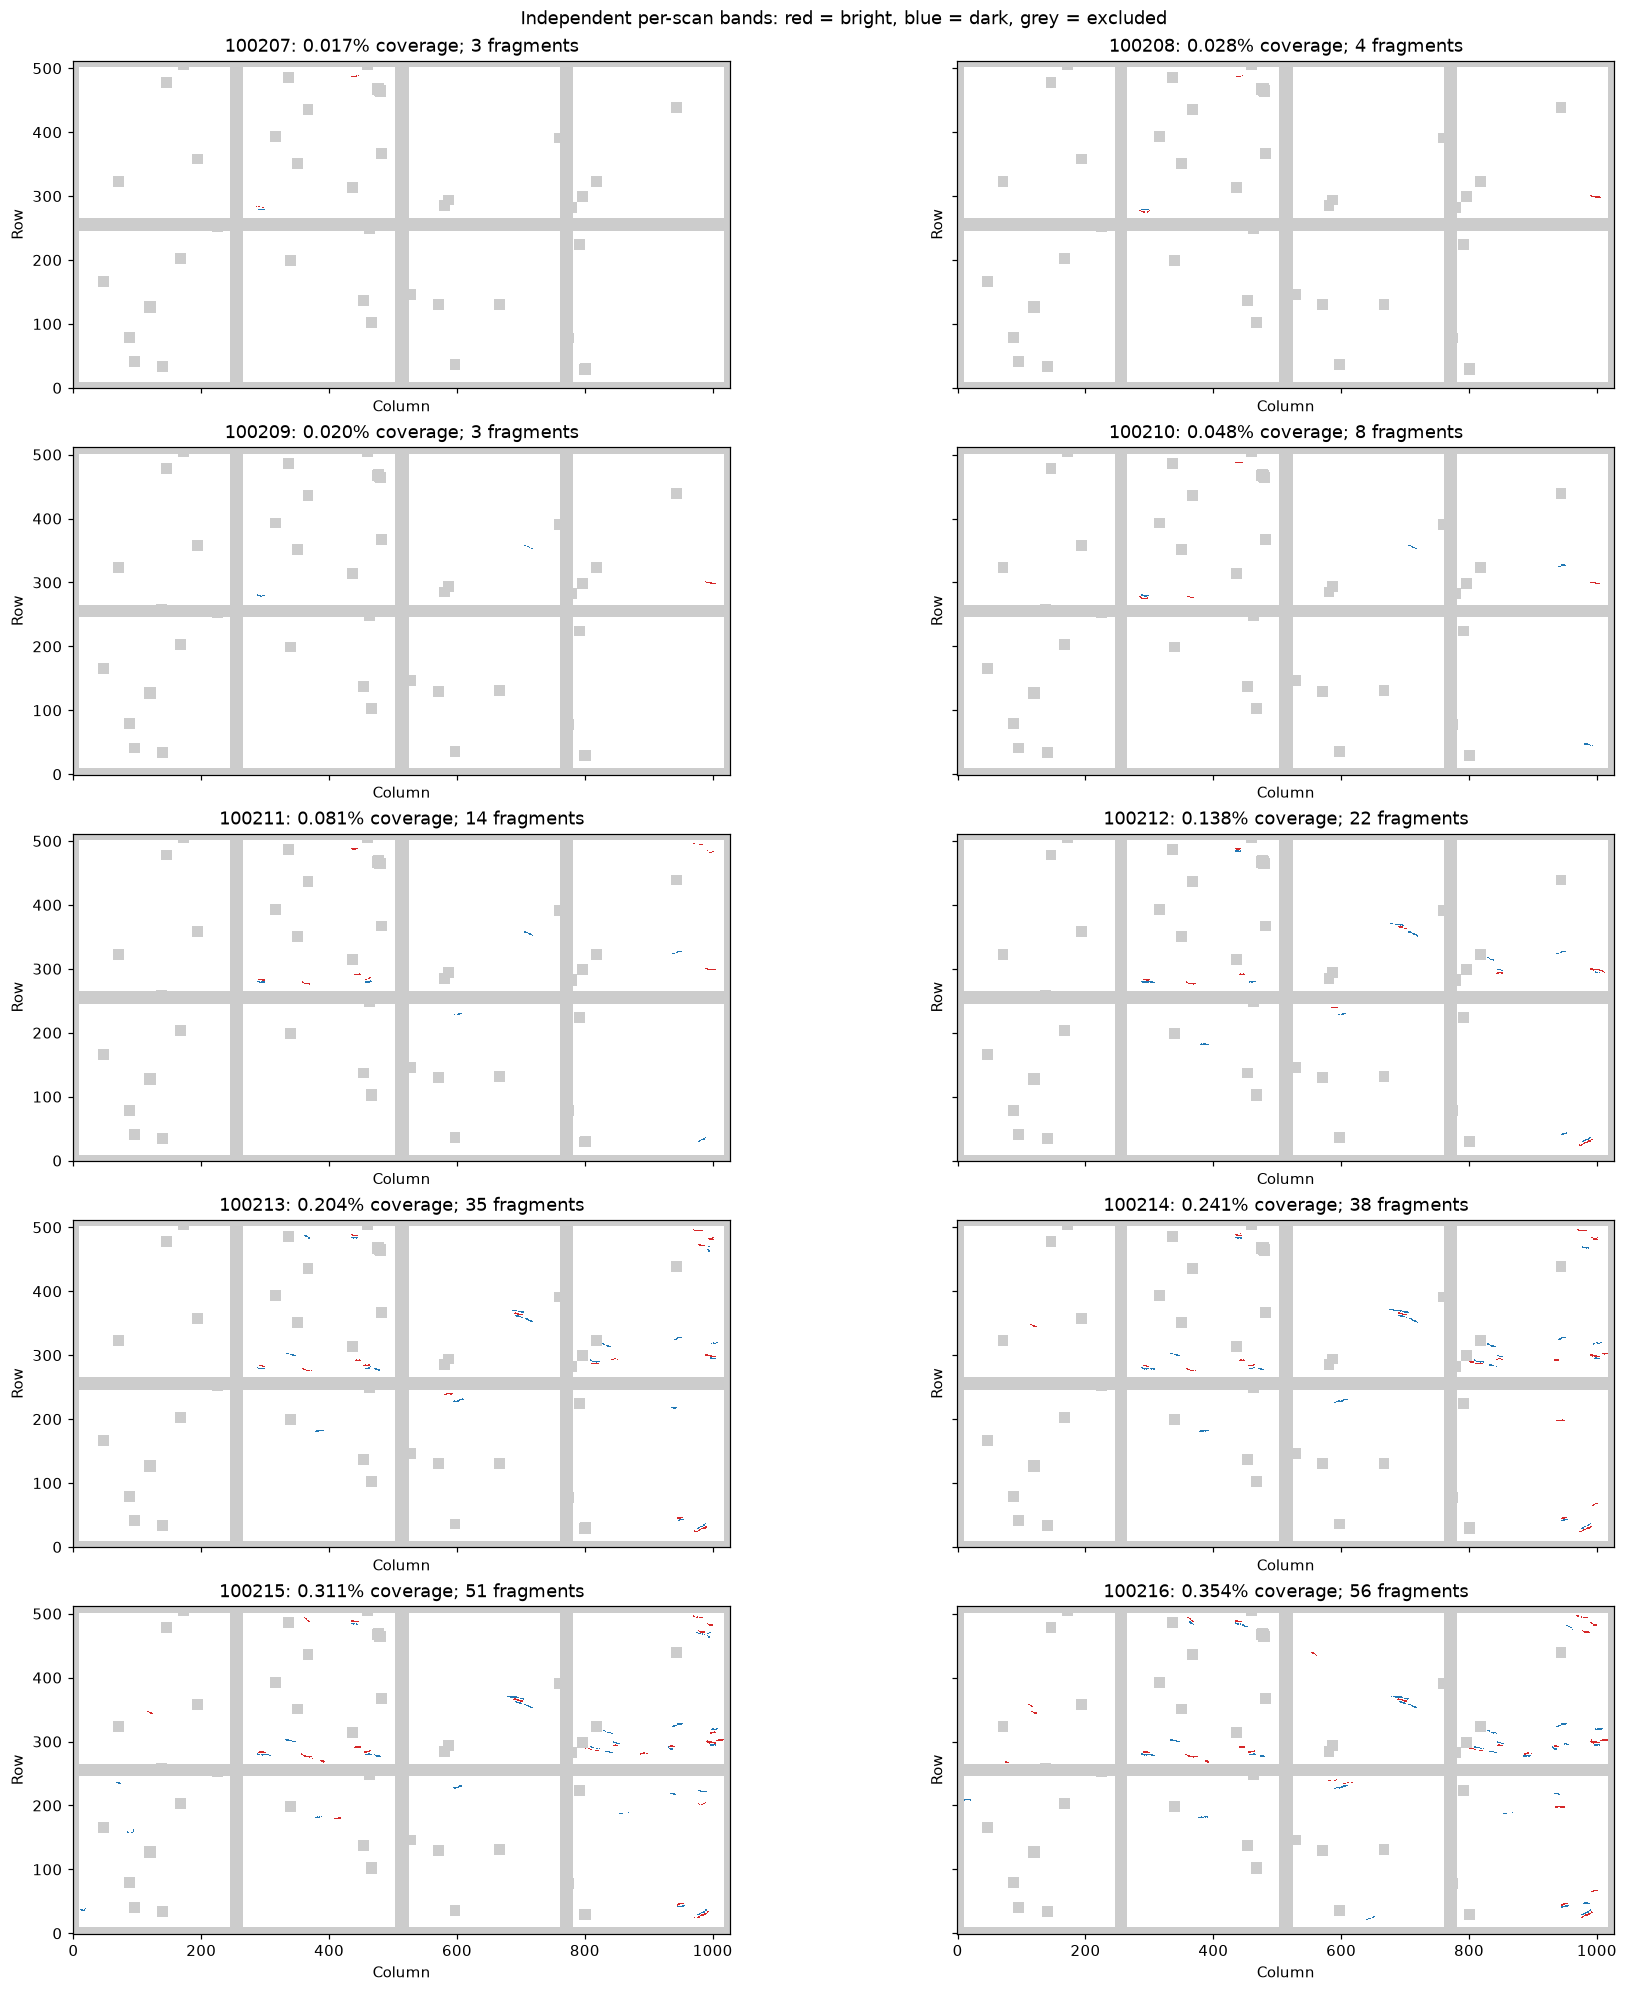

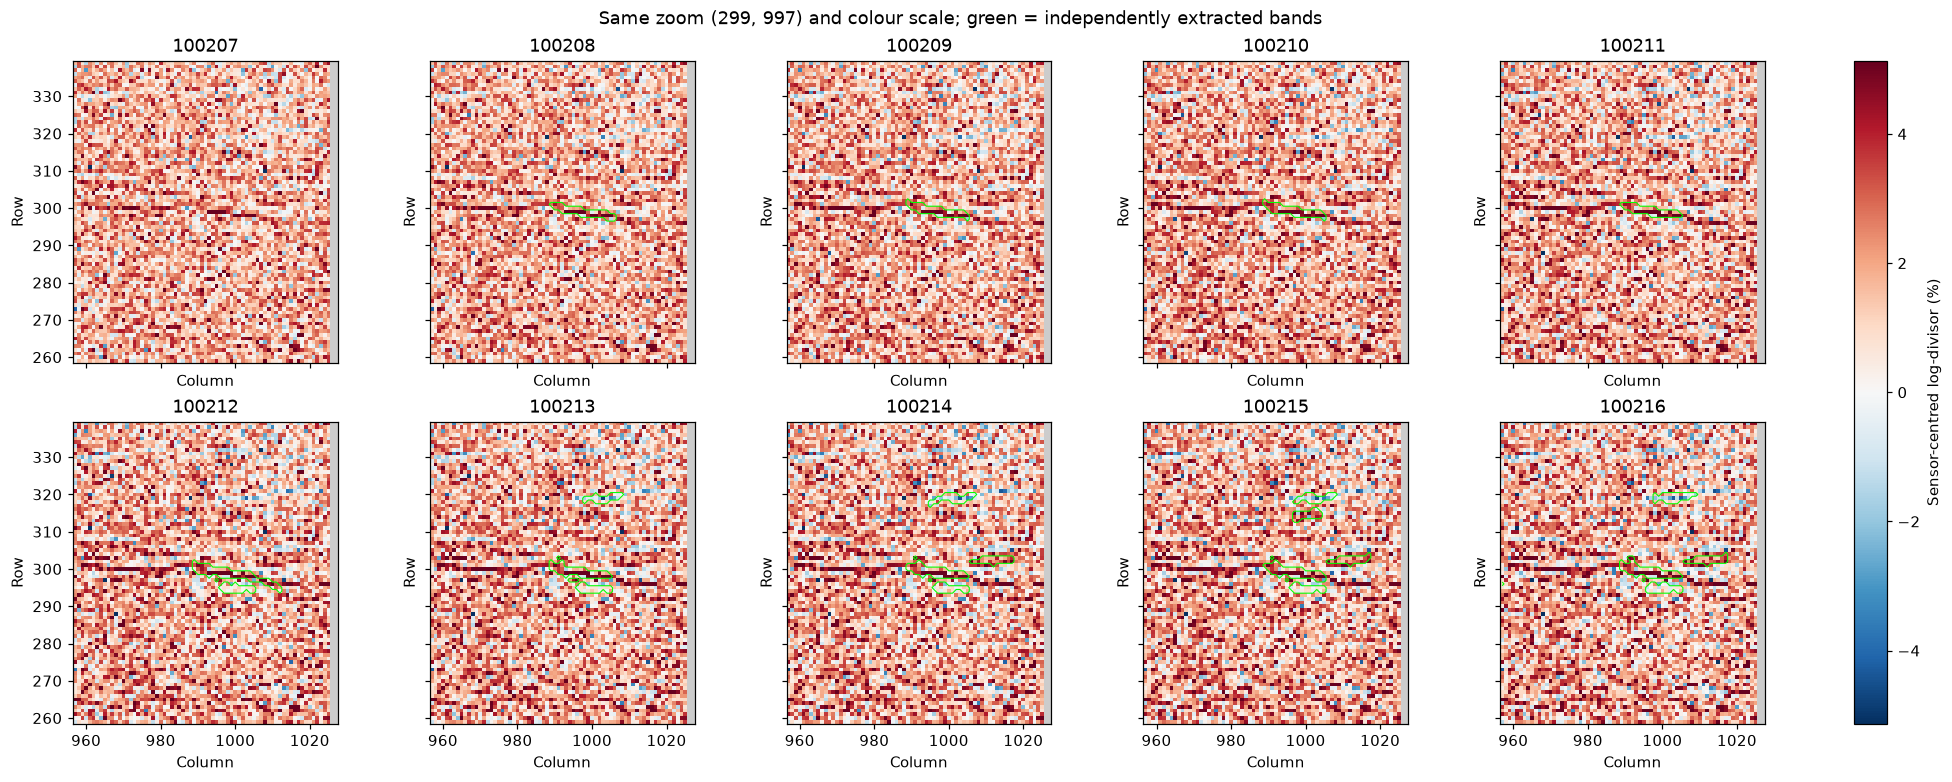

In [23]:
from matplotlib.colors import ListedColormap

band_cmap = ListedColormap(['white', 'tab:blue', 'tab:red'])
band_cmap.set_bad('0.8')
fig, axes = plt.subplots(5, 2, figsize=(16, 18), constrained_layout=True, sharex=True, sharey=True)
for i, ax in enumerate(axes.flat):
    panel = np.where(repeat_line_masks[i], np.where(repeat_responses[i] > 0, 2, 1), 0)
    ax.imshow(np.ma.masked_where(~ridge_support, panel), origin='lower', cmap=band_cmap,
              vmin=0, vmax=2, interpolation='nearest')
    ax.set(title=f'{SCANS[i]}: {repeat_summary.iloc[i].ridge_area_percent:.3f}% coverage; '
                 f'{int(repeat_summary.iloc[i].fragment_count)} fragments', xlabel='Column', ylabel='Row')
fig.suptitle('Independent per-scan bands: red = bright, blue = dark, grey = excluded')
plt.show()

if ZOOM_CENTRE is None:
    selection = repeat_line_masks[-1] if repeat_line_masks[-1].any() else ridge_support
    centre = tuple(int(value) for value in np.unravel_index(
        np.argmax(np.where(selection, np.abs(repeat_responses[-1]), -np.inf)), sensor_ids.shape))
else:
    centre = tuple(int(value) for value in ZOOM_CENTRE)
if len(centre) != 2 or not (0 <= centre[0] < sensor_ids.shape[0] and 0 <= centre[1] < sensor_ids.shape[1]):
    raise ValueError('ZOOM_CENTRE must be an in-bounds (row, column).')
r0, r1 = max(0, centre[0] - ZOOM_HALF_WIDTH), min(sensor_ids.shape[0], centre[0] + ZOOM_HALF_WIDTH + 1)
c0, c1 = max(0, centre[1] - ZOOM_HALF_WIDTH), min(sensor_ids.shape[1], centre[1] + ZOOM_HALF_WIDTH + 1)
zoom = np.s_[r0:r1, c0:c1]
extent = (c0 - 0.5, c1 - 0.5, r0 - 0.5, r1 - 0.5)
map_limit = max(float(np.percentile(np.abs(log_maps[:, common_valid]), 99)), 1e-6)
fig, axes = plt.subplots(2, 5, figsize=(18, 7), constrained_layout=True, sharex=True, sharey=True)
for i, ax in enumerate(axes.flat):
    image = ax.imshow(np.ma.masked_invalid(log_maps[i][zoom]), origin='lower', extent=extent,
                      cmap=cmap, vmin=-map_limit, vmax=map_limit, interpolation='nearest')
    mask = repeat_line_masks[i][zoom]
    if mask.any() and not mask.all():
        ax.contour(mask.astype(float), levels=[0.5], colors='lime', linewidths=0.7,
                   origin='lower', extent=extent)
    ax.set(title=str(SCANS[i]), xlabel='Column', ylabel='Row')
fig.colorbar(image, ax=axes.ravel().tolist(), label='Sensor-centred log-divisor (%)')
fig.suptitle(f'Same zoom {centre} and colour scale; green = independently extracted bands')
plt.show()

## 3. Own-correction 1D patterns and high-angle discontinuities

Process **all raw frames** of each scan with that scan's own correction, using the same `eiger_workflow` integration and accumulator merging as the fast extraction notebook. Apply I0, solid angle, polarisation, CdTe absorption, the saved divisor and saved source-frame gains. Frame gains are allowed here only because each correction belongs to the exact source scan; they are not transferred or refitted. Saved base/bad masks and the scan's native mask are applied independently, as in normal processing.

Use **2000 2θ bins** on a common range from zero to the smallest geometry-derived maximum among these scans. Count variances are propagated as in the fast workflow. Full-range use extrapolates the divisor outside its fitted q interval; the tables report the high-angle fraction inside that interval. This is an **in-sample, best-effort corrected comparison**, not independent validation of calibration quality. Different own-scan bad masks and fitted gains can themselves affect the result.

The default high-angle window is **50–65° 2θ**, clipped to common supported coverage. These are explicit exploratory settings, not selected to maximise a trend. The waterfall uses one scalar median normalisation per pattern over that fixed window and vertical offsets for readability; the unscaled integrated patterns and Poisson sigmas are retained in memory. All source files remain read-only; integration may take several minutes.

In [27]:
import gc
import time
import eiger_workflow as workflow

THETA_POINTS = 2000
HIGH_ANGLE_RANGE = (50.0, 65.0)  # Degrees 2theta; fixed for all scans.
STEP_HALF_WINDOW = 4           # Bins on each side of a candidate jump.
STEP_CANDIDATE_PERCENT = 1.0   # Descriptive local jump threshold, not a significance test.

# Determine one axis before integrating counts. Keep only one physical model alive at a time.
integration_sources, maxima = [], []
for scan_number, calibration_path in zip(SCANS, paths):
    scan_1d = workflow.load_scan(RAW_DIRECTORY / f'i15-1-{scan_number}.nxs')
    calibration_1d = workflow.load_calibration(calibration_path)
    if str(scan_1d.path) != calibration_1d['source_scan']:
        raise ValueError('Own-correction integration requires exact source-scan provenance.')
    np.testing.assert_array_equal(scan_1d.angles, calibration_1d['frame_angles'])
    np.testing.assert_array_equal(scan_1d.i0, calibration_1d['frame_i0'])
    model_1d = workflow.model_for_processing(scan_1d, calibration_1d)
    applied_mask = (calibration_1d['base_mask'].astype(bool)
                    | calibration_1d['bad_pixel_mask'].astype(bool) | scan_1d.native_mask)
    maxima.append(workflow.theta_range_for_scan(scan_1d, model_1d, applied_mask)[1])
    integration_sources.append((scan_1d, calibration_path))
    del model_1d, calibration_1d
    gc.collect()
common_theta_range = (0.0, float(min(maxima)))
print(f'Integrating {len(SCANS)} scans, {THETA_POINTS} bins over {common_theta_range} degrees.', flush=True)

patterns_1d, integration_rows = [], []
for scan_number, (scan_1d, calibration_path) in zip(SCANS, integration_sources):
    started = time.perf_counter()
    calibration_1d = workflow.load_calibration(calibration_path)
    model_1d = workflow.model_for_processing(scan_1d, calibration_1d)
    processed_1d = workflow.process_scan(
        scan_1d, calibration_1d, model_1d,
        q_range=tuple(calibration_1d['fit_settings']['q_range']),
        q_npt=int(calibration_1d['fit_settings']['npt']),
        theta_npt=THETA_POINTS, theta_range=common_theta_range,
        apply_calibration_frame_gains=True, allow_extrapolation=True, saturation=RAW_SATURATION)
    np.testing.assert_array_equal(processed_1d['frame_gains'], calibration_1d['frame_gains'])
    group_1d = processed_1d['groups']['merged_2theta']
    patterns_1d.append({key: np.array(group_1d[key], copy=True) for key in
                        ('axis', 'intensity', 'sigma', 'accumulators', 'within_fit_range')})
    integration_rows.append({'scan': int(scan_number), 'frames': len(scan_1d.angles),
                             'masked_pixels': int(processed_1d['mask'].sum()),
                             'calibration_path': str(calibration_path),
                             'source_frame_gains_applied': True,
                             'seconds': time.perf_counter() - started})
    print(f'{scan_number}: integrated {len(scan_1d.angles)} frames in '
          f'{integration_rows[-1]["seconds"]:.1f} s', flush=True)
    del processed_1d, model_1d, calibration_1d
    gc.collect()

two_theta = patterns_1d[0]['axis']
for pattern in patterns_1d:
    np.testing.assert_allclose(pattern['axis'], two_theta, rtol=0, atol=1e-10)
    assert len(pattern['axis']) == THETA_POINTS
intensity_1d = np.stack([pattern['intensity'] for pattern in patterns_1d])
sigma_1d = np.stack([pattern['sigma'] for pattern in patterns_1d])
normalisation_1d = np.stack([pattern['accumulators'][1] for pattern in patterns_1d])
common_1d = np.all(np.isfinite(intensity_1d) & (intensity_1d > 0)
                   & np.isfinite(sigma_1d) & (sigma_1d >= 0) & (normalisation_1d > 0), axis=0)
high_angle_support = common_1d & (two_theta >= HIGH_ANGLE_RANGE[0]) & (two_theta <= HIGH_ANGLE_RANGE[1])
if high_angle_support.sum() < 4 * STEP_HALF_WINDOW:
    raise ValueError('Too little common high-angle support; inspect HIGH_ANGLE_RANGE and coverage.')
integration_summary = pd.DataFrame(integration_rows).set_index('scan')
integration_summary['high_angle_bins'] = int(high_angle_support.sum())
integration_summary['high_angle_fraction_inside_fit_q'] = [
    pattern['within_fit_range'][high_angle_support].mean() for pattern in patterns_1d]
display(integration_summary)
print(f'High-angle bins: {high_angle_support.sum()}; bin width {np.median(np.diff(two_theta)):.5f} degrees.')

Integrating 10 scans, 2000 bins over (0.0, 67.27947079760088) degrees.


100207: integrated 162 frames in 24.0 s


100208: integrated 162 frames in 25.3 s


100209: integrated 162 frames in 25.2 s


100210: integrated 162 frames in 25.0 s


...

100214: integrated 162 frames in 24.8 s


100215: integrated 162 frames in 26.1 s


100216: integrated 162 frames in 26.0 s


,frames,masked_pixels,calibration_path,source_frame_gains_applied,seconds,high_angle_bins,high_angle_fraction_inside_fit_q
scan,,,,,,,
100207,162,17334,/scratch/fer45166/eiger-correction/outputs/cro...,True,24.015386,446,0.795964
100208,162,17334,/scratch/fer45166/eiger-correction/outputs/cro...,True,25.316097,446,0.795964
100209,162,17337,/scratch/fer45166/eiger-correction/outputs/cro...,True,25.179490,446,0.795964
100210,162,17342,/scratch/fer45166/eiger-correction/outputs/cro...,True,25.013430,446,0.795964
100211,162,17342,/scratch/fer45166/eiger-correction/outputs/cro...,True,25.094045,446,0.795964
100212,162,17344,/scratch/fer45166/eiger-correction/outputs/cro...,True,24.826120,446,0.795964
100213,162,17345,/scratch/fer45166/eiger-correction/outputs/cro...,True,24.913726,446,0.795964
100214,162,17346,/scratch/fer45166/eiger-correction/outputs/cro...,True,24.771353,446,0.795964
100215,162,17350,/scratch/fer45166/eiger-correction/outputs/cro...,True,26.061830,446,0.795964


High-angle bins: 446; bin width 0.03364 degrees.


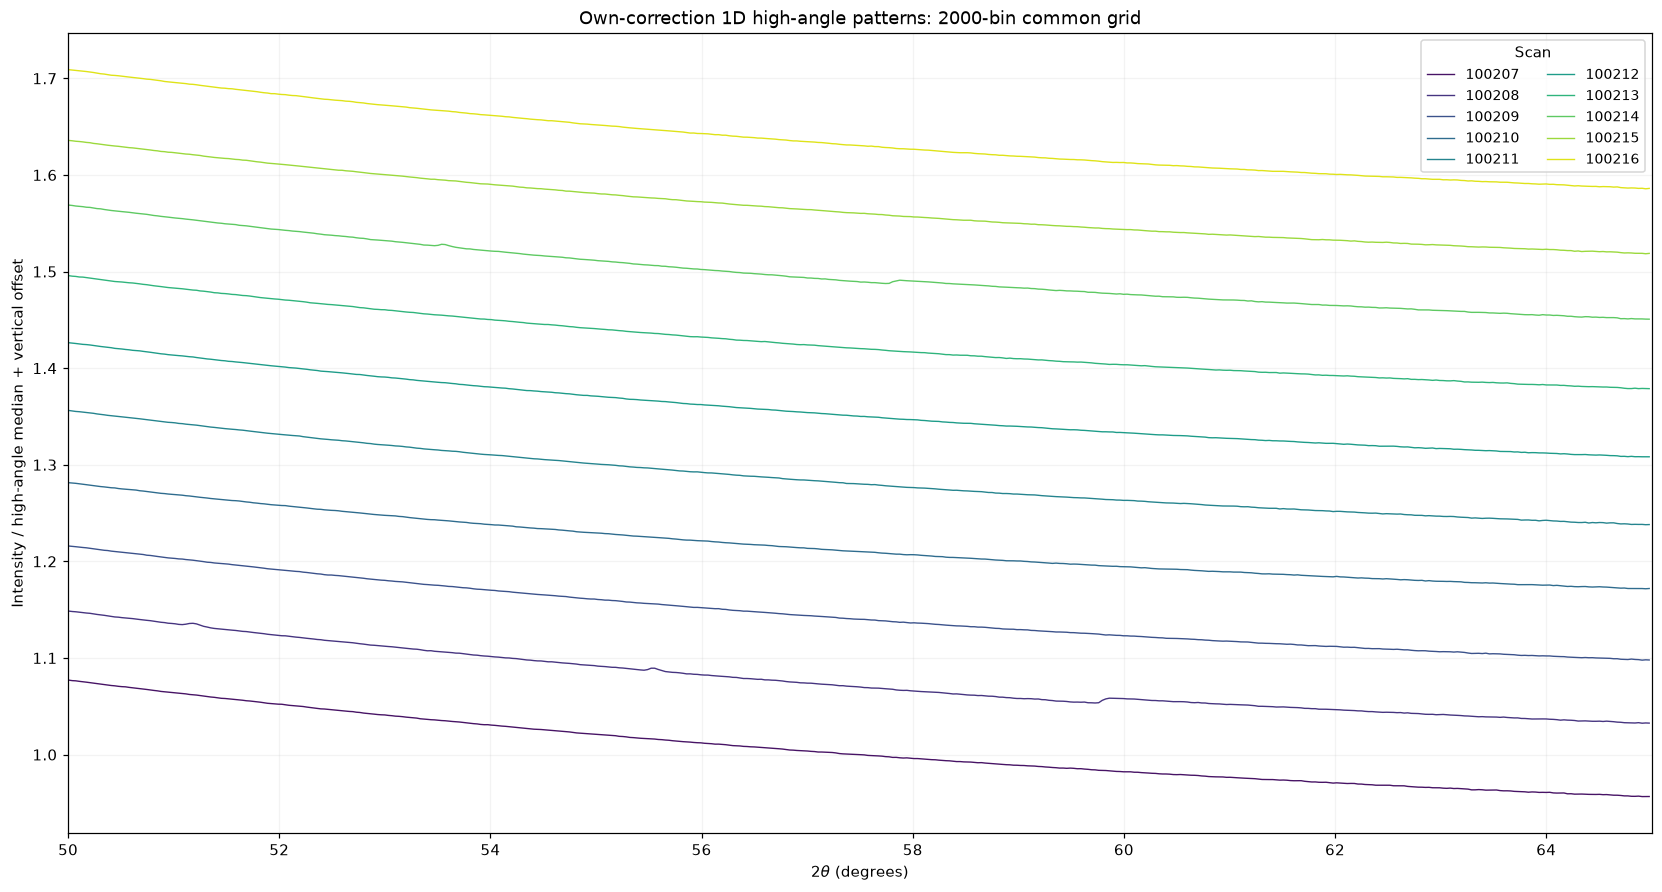

Waterfall offset: 0.07005 median-normalised intensity units; normalisation is for display, not a per-angle response correction.


In [28]:
# Waterfall of corrected diffraction patterns: no smoothing, regridding or peak alignment.
pattern_scale = np.median(intensity_1d[:, high_angle_support], axis=1)
scaled_patterns = intensity_1d / pattern_scale[:, None]
high_values = scaled_patterns[:, high_angle_support]
waterfall_offset = max(float(np.ptp(np.percentile(high_values, [1, 99]))) * 0.6, 0.05)
pattern_colours = plt.get_cmap('viridis')(np.linspace(0.05, 0.95, len(SCANS)))
fig, ax = plt.subplots(figsize=(15, 8), constrained_layout=True)
for i, scan_number in enumerate(SCANS):
    panel = np.where(high_angle_support, scaled_patterns[i], np.nan)
    ax.plot(two_theta, panel + i * waterfall_offset, lw=0.9, color=pattern_colours[i], label=str(scan_number))
ax.set(xlim=HIGH_ANGLE_RANGE, xlabel=r'$2\theta$ (degrees)',
       ylabel='Intensity / high-angle median + vertical offset',
       title='Own-correction 1D high-angle patterns: 2000-bin common grid')
ax.legend(title='Scan', ncol=2, fontsize=9)
ax.grid(alpha=0.15)
plt.show()
print(f'Waterfall offset: {waterfall_offset:.4g} median-normalised intensity units; '
      'normalisation is for display, not a per-angle response correction.')

### A local discontinuity proxy, not a peak/defect classifier

For each candidate boundary in 50–65°, fit a straight line to **four bins on each side** and extrapolate both lines to the boundary. Their difference estimates a local jump while cancelling a constant or linear background. Compute this on `100 × log(intensity)` and on its difference from the **binwise median log pattern across these ten scans**. The second version removes the shared diffraction shape; it still responds to changing peaks, misalignment, noise and integration/mask artefacts, and removes discontinuities shared by every scan. It is called **differential jump**, not absolute detector damage.

The main metric is the **95th percentile of the absolute differential jump**, in log-percent (approximately percent for small values), on identical supported boundaries for every scan. Also show its maximum, RMS, and number of separated local maxima above the fixed 1-log-percent exploratory threshold. We report the unreferenced jump percentile too, so shared pattern structure is not silently discarded. No gaps are bridged. A four-bin side spans about 0.135° here; results depend on that scale and on the 2000-bin grid.

The reference includes these scans, so these are descriptive comparisons, not held-out tests. No Poisson-significance labels are assigned: pyFAI pixel splitting correlates bins and the reported Poisson sigmas exclude I0/calibration/model uncertainty. Candidate counts are not counts of physical discontinuities. The extra 800-bin q integrations performed by `process_scan` can warn about empty low-angle frames outside the fitted q range; only supported **2000-bin 2θ** accumulators enter this analysis.

,jump_p95_log_percent,jump_rms_log_percent,jump_max_log_percent,candidate_count,unreferenced_jump_p95_log_percent
scan,,,,,
100207,0.04014,0.02021,0.07451,0,0.03983
100208,0.05765,0.03697,0.28818,0,0.05726
100209,0.03753,0.01700,0.07183,0,0.03505
100210,0.03532,0.01876,0.06378,0,0.03414
100211,0.03782,0.01987,0.08868,0,0.03880
100212,0.02108,0.01095,0.04143,0,0.03553
100213,0.03353,0.01811,0.06640,0,0.03430
100214,0.04592,0.02805,0.20551,0,0.04549
100215,0.03734,0.01842,0.06371,0,0.03579


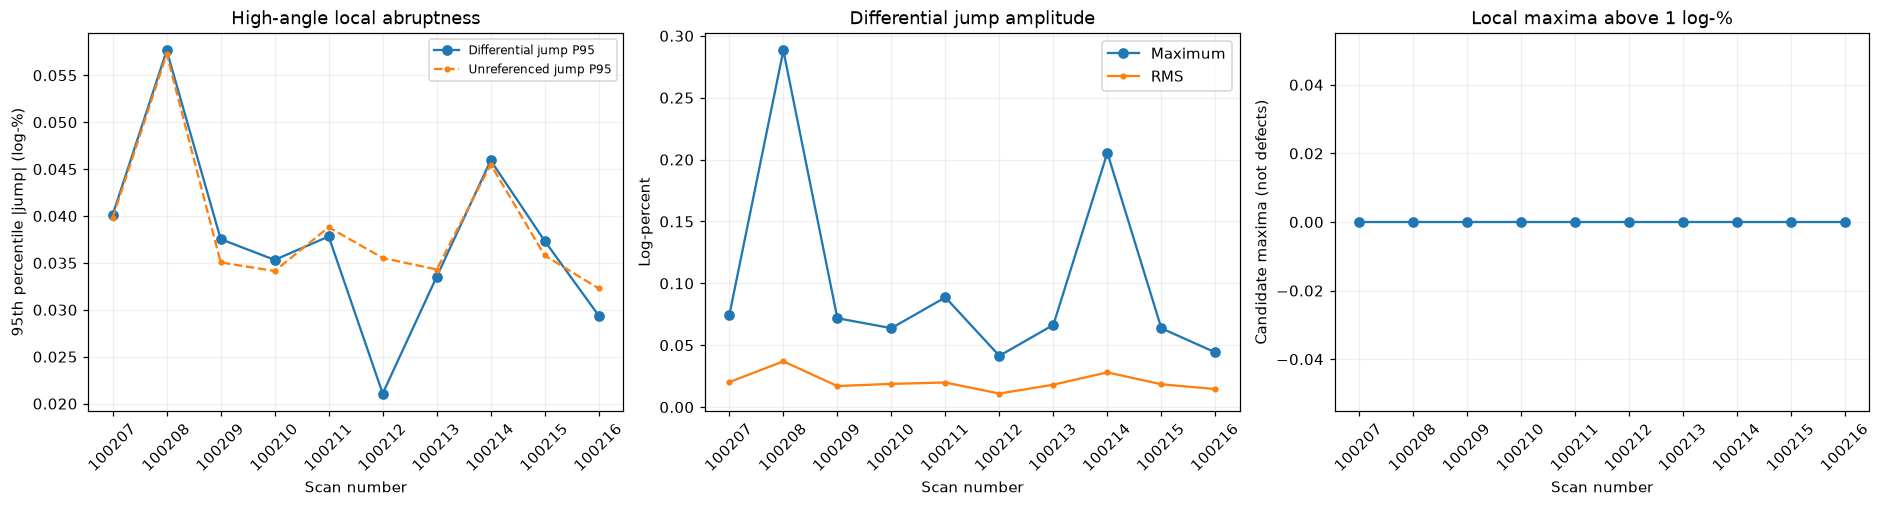

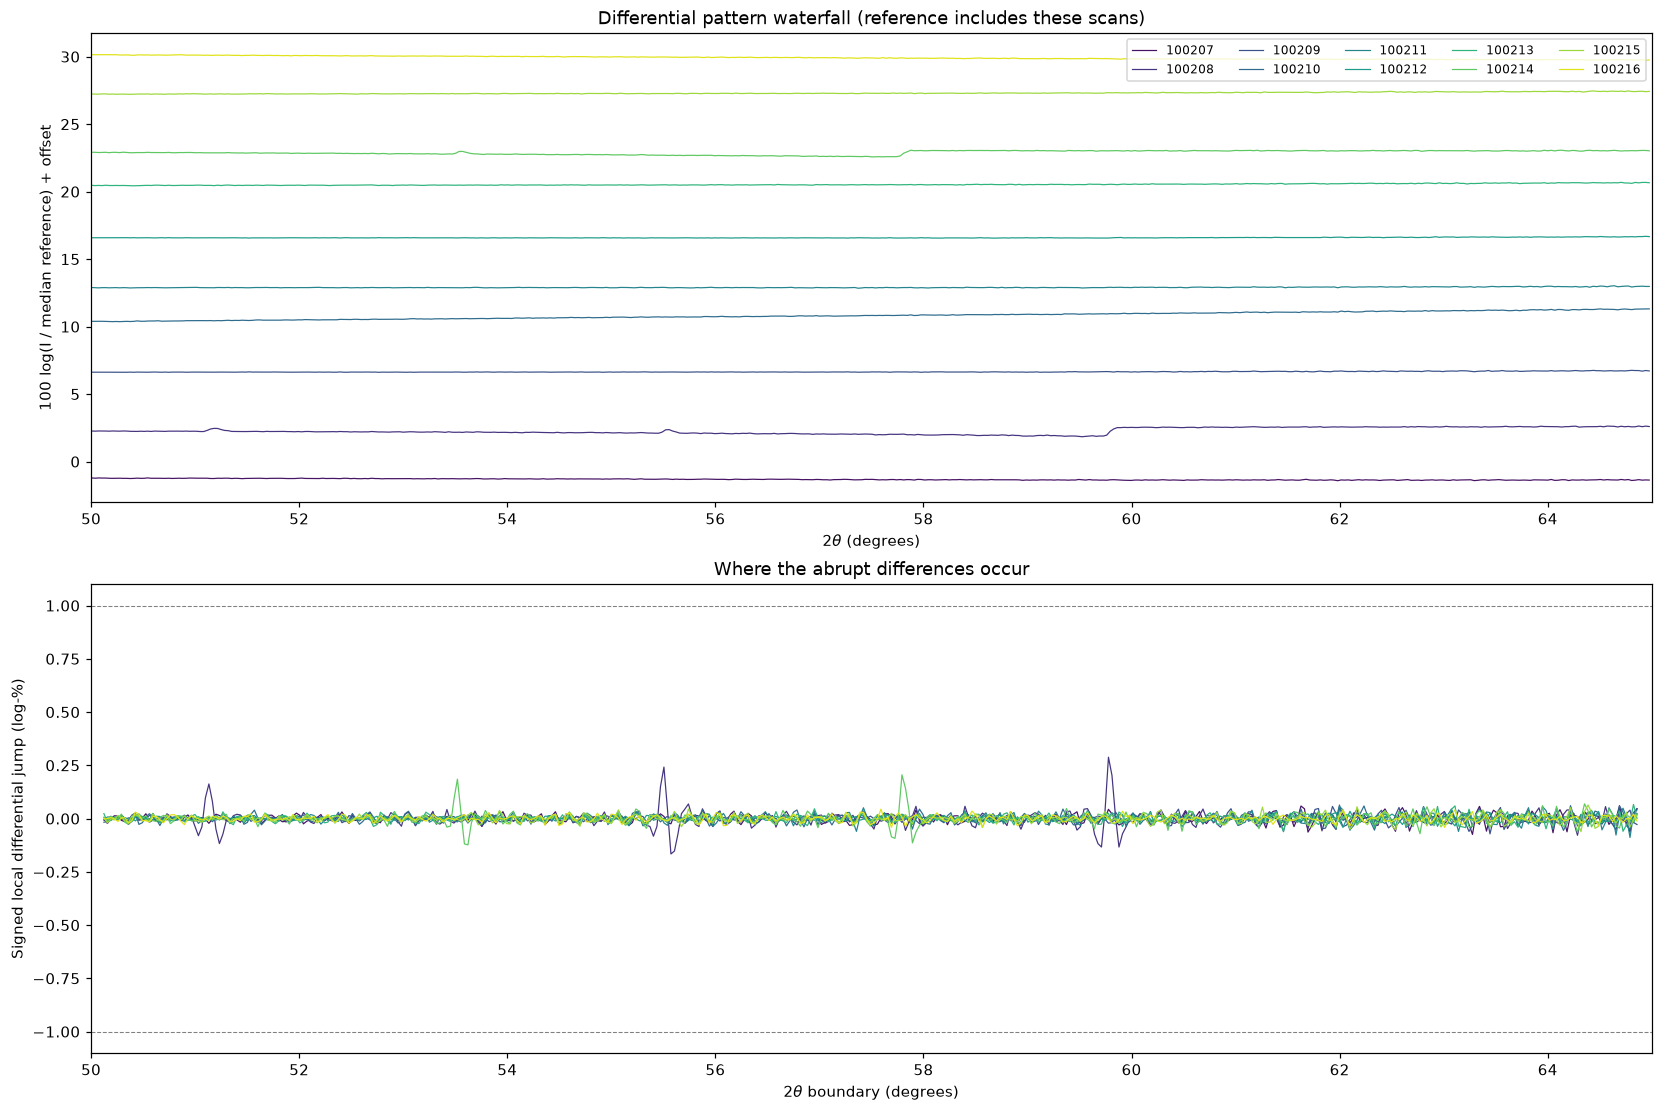

In [29]:
from scipy.signal import find_peaks
from scipy.stats import spearmanr

# Linear-fit intercept at a boundary halfway between adjacent bins.
h = STEP_HALF_WINDOW
assert isinstance(h, int) and h >= 2
x_left = np.arange(-h, 0, dtype=float) + 0.5
x_right = np.arange(0, h, dtype=float) + 0.5
left_weights = np.linalg.pinv(np.column_stack((np.ones(h), x_left)))[0]
right_weights = np.linalg.pinv(np.column_stack((np.ones(h), x_right)))[0]
jump_weights = np.r_[-left_weights, right_weights]
# Prove the estimator cancels constants/slopes and recovers a known unit step.
np.testing.assert_allclose(jump_weights.sum(), 0, atol=1e-12)
np.testing.assert_allclose(jump_weights @ np.r_[x_left, x_right], 0, atol=1e-12)
np.testing.assert_allclose(jump_weights @ np.r_[np.zeros(h), np.ones(h)], 1, atol=1e-12)

boundary_indices = np.array([j for j in range(h, THETA_POINTS - h + 1)
                             if high_angle_support[j-h:j+h].all()], dtype=int)
if not len(boundary_indices):
    raise ValueError('No fully supported local jump windows.')
jump_angles = (two_theta[boundary_indices - 1] + two_theta[boundary_indices]) / 2
log_patterns = np.full_like(intensity_1d, np.nan)
log_patterns[:, common_1d] = 100 * np.log(intensity_1d[:, common_1d])
reference_log_pattern = np.full(THETA_POINTS, np.nan)
reference_log_pattern[common_1d] = np.median(log_patterns[:, common_1d], axis=0)
log_ratio_patterns = log_patterns - reference_log_pattern[None, :]
absolute_jumps = np.stack([log_patterns[:, j-h:j+h] @ jump_weights for j in boundary_indices], axis=1)
differential_jumps = np.stack([log_ratio_patterns[:, j-h:j+h] @ jump_weights for j in boundary_indices], axis=1)

metric_rows, candidate_rows = [], []
for i, scan_number in enumerate(SCANS):
    values = np.abs(differential_jumps[i])
    # Split by real bin adjacency so no peak selection bridges unsupported gaps.
    candidates = []
    for segment in np.split(np.arange(len(boundary_indices)), np.flatnonzero(np.diff(boundary_indices) > 1) + 1):
        if not len(segment):
            continue
        positions, _ = find_peaks(values[segment], height=STEP_CANDIDATE_PERCENT, distance=2*h)
        candidates.extend(segment[positions].tolist())
    metric_rows.append({'scan': int(scan_number),
                        'jump_p95_log_percent': float(np.percentile(values, 95)),
                        'jump_rms_log_percent': float(np.sqrt(np.mean(values**2))),
                        'jump_max_log_percent': float(values.max()),
                        'candidate_count': len(candidates),
                        'unreferenced_jump_p95_log_percent': float(np.percentile(np.abs(absolute_jumps[i]), 95))})
    for k in candidates:
        candidate_rows.append({'scan': int(scan_number), 'two_theta_deg': float(jump_angles[k]),
                               'signed_differential_jump_log_percent': float(differential_jumps[i, k])})
discontinuity_metrics = pd.DataFrame(metric_rows).set_index('scan')
discontinuity_candidates = pd.DataFrame(candidate_rows, columns=[
    'scan', 'two_theta_deg', 'signed_differential_jump_log_percent'])
combined_metrics = prevalence.join(discontinuity_metrics)
display(discontinuity_metrics.round(5))
if len(discontinuity_candidates):
    display(discontinuity_candidates)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), constrained_layout=True)
axes[0].plot(SCANS, discontinuity_metrics['jump_p95_log_percent'], 'o-', label='Differential jump P95')
axes[0].plot(SCANS, discontinuity_metrics['unreferenced_jump_p95_log_percent'], '.--', label='Unreferenced jump P95')
axes[0].set(title='High-angle local abruptness', ylabel='95th percentile |jump| (log-%)')
axes[0].legend(fontsize=8)
axes[1].plot(SCANS, discontinuity_metrics['jump_max_log_percent'], 'o-', label='Maximum')
axes[1].plot(SCANS, discontinuity_metrics['jump_rms_log_percent'], '.-', label='RMS')
axes[1].set(title='Differential jump amplitude', ylabel='Log-percent')
axes[1].legend()
axes[2].plot(SCANS, discontinuity_metrics['candidate_count'], 'o-')
axes[2].set(title=f'Local maxima above {STEP_CANDIDATE_PERCENT:g} log-%', ylabel='Candidate maxima (not defects)')
for ax in axes:
    ax.set_xlabel('Scan number')
    ax.set_xticks(SCANS)
    ax.ticklabel_format(axis='x', style='plain', useOffset=False)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(alpha=0.2)
plt.show()

# Residual waterfall magnifies differences hidden by the common smooth diffraction background.
residual_limit = max(float(np.percentile(np.abs(log_ratio_patterns[:, high_angle_support]), 99)), 0.1)
residual_offset = 2.4 * residual_limit
fig, axes = plt.subplots(2, 1, figsize=(15, 10), constrained_layout=True)
for i, scan_number in enumerate(SCANS):
    axes[0].plot(two_theta, np.where(high_angle_support, log_ratio_patterns[i], np.nan) + i * residual_offset,
                 color=pattern_colours[i], lw=0.8, label=str(scan_number))
    axes[1].plot(jump_angles, differential_jumps[i], color=pattern_colours[i], lw=0.8, label=str(scan_number))
axes[0].set(xlim=HIGH_ANGLE_RANGE, xlabel=r'$2\theta$ (degrees)',
            ylabel='100 log(I / median reference) + offset', title='Differential pattern waterfall (reference includes these scans)')
axes[0].legend(ncol=5, fontsize=8)
axes[1].axhline(STEP_CANDIDATE_PERCENT, color='0.5', ls='--', lw=0.7)
axes[1].axhline(-STEP_CANDIDATE_PERCENT, color='0.5', ls='--', lw=0.7)
axes[1].set(xlim=HIGH_ANGLE_RANGE, xlabel=r'$2\theta$ boundary (degrees)',
            ylabel='Signed local differential jump (log-%)', title='Where the abrupt differences occur')
plt.show()

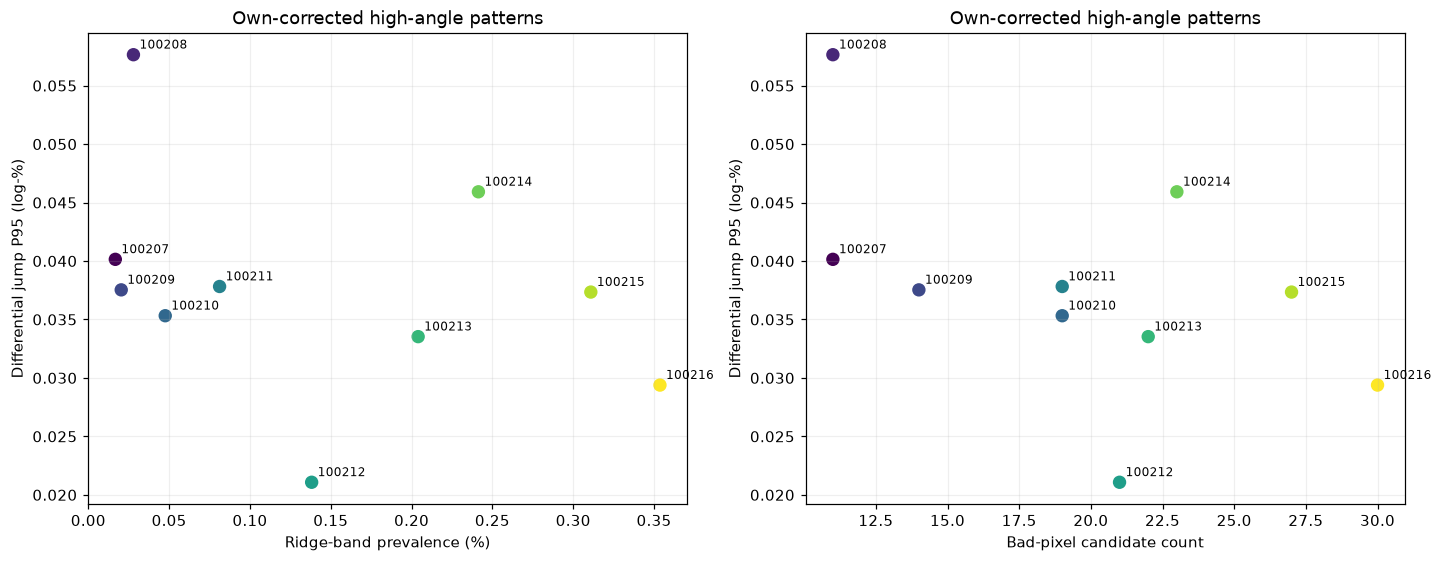

,spearman_with_jump_p95
indicator,
ridge_area_percent,-0.454545
bad_fixed_count,-0.536595


,first_scan_p95,last_scan_p95,spearman_vs_scan
side_bins,,,
2,0.05520,0.03971,-0.34545
4,0.04014,0.02939,-0.50303
8,0.02855,0.02282,-0.35758


,strongest_jump_tth_deg,signed_jump_log_percent
scan,,
100207,63.27635,-0.07451
100208,59.77782,0.28818
100209,63.44455,-0.07183
100210,61.99804,0.06378
100211,64.79014,-0.08868
100212,62.03168,-0.04143
100213,64.82378,0.06640
100214,57.79307,0.20551
100215,64.38646,0.06371


### Conclusions for this ten-scan sequence

- **The extracted detector indicators increase:** bad-pixel candidates rise from 11 to 30, and ridge-band coverage from 0.0167% to 0.3537% of the fixed ridge area.
- **That increase is not mirrored by this corrected 1D abruptness metric:** the differential-jump P95 is 0.0401 → 0.0294 log-%, with descriptive scan-order Spearman rho = -0.503. The largest individual local jump is 0.288 log-% in scan 100208; 0 maxima exceed the fixed 1-log-% threshold.
- **Do not equate correction severity with residual pattern degradation.** Own-scan divisors, masks, frame gains and angular averaging may compensate or dilute detector structure; this comparison does not isolate which mechanism matters. Small local differences remain visible in the residual waterfall.
- **Reset strategy:** these data motivate monitoring both detector-map indicators and an independently defined diffraction-quality limit, but do not yet establish a trigger. Test before/after reset and on held-out scans or a stable external standard, including a no-correction/fixed-correction control, to establish whether an indicator threshold predicts unacceptable patterns. No detector reset is performed here.

Correlations use only ten ordered, related scans and are descriptive (no independent-replicate p-values). The metric measures local departures from a shared pattern at one angular scale, not all discontinuities; it can miss broad changes or defects common to every scan and can respond to sample changes. About 20% of the selected high-angle bins extrapolate outside the divisor-fit q range.

1D validation passed: common 2000-bin grid, accumulator intensity/sigma reconstruction, fixed metric windows and synthetic step/slope checks.


In [30]:
# Relate whole-detector indicators to the primary discontinuity proxy, with scan labels.
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
association_rows = []
for ax, field, text in zip(axes, ('ridge_area_percent', 'bad_fixed_count'),
                           ('Ridge-band prevalence (%)', 'Bad-pixel candidate count')):
    ax.scatter(combined_metrics[field], combined_metrics['jump_p95_log_percent'], c=SCANS,
               cmap='viridis', s=60)
    for scan_number, row in combined_metrics.iterrows():
        ax.annotate(str(scan_number), (row[field], row['jump_p95_log_percent']),
                    xytext=(4, 4), textcoords='offset points', fontsize=8)
    ax.set(xlabel=text, ylabel='Differential jump P95 (log-%)', title='Own-corrected high-angle patterns')
    ax.grid(alpha=0.2)
    association_rows.append({'indicator': field,
                             'spearman_with_jump_p95': float(spearmanr(combined_metrics[field],
                                                                      combined_metrics['jump_p95_log_percent']).statistic)})
plt.show()
association_summary = pd.DataFrame(association_rows).set_index('indicator')
display(association_summary)

# Fixed-scale sensitivity check: repeat only the cheap metric, not integration.
sensitivity_rows = []
for half_width in (2, 4, 8):
    xl = np.arange(-half_width, 0, dtype=float) + 0.5
    xr = np.arange(half_width, dtype=float) + 0.5
    weights = np.r_[-np.linalg.pinv(np.column_stack((np.ones(half_width), xl)))[0],
                     np.linalg.pinv(np.column_stack((np.ones(half_width), xr)))[0]]
    centres = [j for j in range(half_width, THETA_POINTS-half_width+1)
               if high_angle_support[j-half_width:j+half_width].all()]
    estimates = np.stack([log_ratio_patterns[:, j-half_width:j+half_width] @ weights for j in centres], axis=1)
    p95 = np.percentile(np.abs(estimates), 95, axis=1)
    sensitivity_rows.append({'side_bins': half_width, 'first_scan_p95': p95[0], 'last_scan_p95': p95[-1],
                              'spearman_vs_scan': float(spearmanr(SCANS, p95).statistic)})
metric_sensitivity = pd.DataFrame(sensitivity_rows).set_index('side_bins')
display(metric_sensitivity.round(5))

strongest_rows = []
for i, scan_number in enumerate(SCANS):
    k = int(np.argmax(np.abs(differential_jumps[i])))
    strongest_rows.append({'scan': int(scan_number), 'strongest_jump_tth_deg': jump_angles[k],
                           'signed_jump_log_percent': differential_jumps[i, k]})
strongest_jumps = pd.DataFrame(strongest_rows).set_index('scan')
display(strongest_jumps.round(5))

from IPython.display import Markdown
first_metrics, last_metrics = combined_metrics.iloc[0], combined_metrics.iloc[-1]
scan_rho = float(spearmanr(SCANS, combined_metrics['jump_p95_log_percent']).statistic)
worst_scan = int(combined_metrics['jump_max_log_percent'].idxmax())
worst_jump = float(combined_metrics.loc[worst_scan, 'jump_max_log_percent'])
display(Markdown(
    '### Conclusions for this ten-scan sequence\n\n'
    f'- **The extracted detector indicators increase:** bad-pixel candidates rise from '
    f'{int(first_metrics.bad_fixed_count)} to {int(last_metrics.bad_fixed_count)}, and ridge-band coverage from '
    f'{first_metrics.ridge_area_percent:.4f}% to {last_metrics.ridge_area_percent:.4f}% of the fixed ridge area.\n'
    f'- **That increase is not mirrored by this corrected 1D abruptness metric:** the differential-jump P95 '
    f'is {first_metrics.jump_p95_log_percent:.4f} → {last_metrics.jump_p95_log_percent:.4f} log-%, '
    f'with descriptive scan-order Spearman rho = {scan_rho:.3f}. '
    f'The largest individual local jump is {worst_jump:.3f} log-% in scan {worst_scan}; '
    f'{int(combined_metrics.candidate_count.sum())} maxima exceed the fixed {STEP_CANDIDATE_PERCENT:g}-log-% threshold.\n'
    '- **Do not equate correction severity with residual pattern degradation.** Own-scan divisors, masks, '
    'frame gains and angular averaging may compensate or dilute detector structure; this comparison does not '
    'isolate which mechanism matters. Small local differences remain visible in the residual waterfall.\n'
    '- **Reset strategy:** these data motivate monitoring both detector-map indicators and an independently '
    'defined diffraction-quality limit, but do not yet establish a trigger. Test before/after reset and on held-out '
    'scans or a stable external standard, including a no-correction/fixed-correction control, to establish '
    'whether an indicator threshold predicts unacceptable patterns. No detector reset is performed here.\n\n'
    'Correlations use only ten ordered, related scans and are descriptive (no independent-replicate p-values). '
    'The metric measures local departures from a shared pattern at one angular scale, not all discontinuities; '
    'it can miss broad changes or defects common to every scan and can respond to sample changes. '
    'About 20% of the selected high-angle bins extrapolate outside the divisor-fit q range.'))

# Validate merged 2theta products without relying on irrelevant empty q-frame accumulators.
for pattern in patterns_1d:
    totals = pattern['accumulators']
    good = totals[1] > 0
    assert totals.shape == (4, THETA_POINTS)
    assert np.all(np.isfinite(totals))
    np.testing.assert_allclose(pattern['intensity'][good], totals[0, good] / totals[1, good])
    np.testing.assert_allclose(pattern['sigma'][good], np.sqrt(totals[2, good]) / totals[1, good])
assert np.all(np.isfinite(differential_jumps))
assert combined_metrics.index.equals(pd.Index(SCANS, name='scan'))
print('1D validation passed: common 2000-bin grid, accumulator intensity/sigma reconstruction, '
      'fixed metric windows and synthetic step/slope checks.')

### Follow-up: why do 100208 and 100214 stand out?

Compare raw-count sums, I0 and saved frame gains at identical frame indices across all repeats. Ratios below use the median across repeats at that same index, on a fixed base-mask area. These whole-detector sums are an acquisition diagnostic, not another diffraction correction.

For the two suspect scans, re-integrate diagnostically with the **same saved calibration, physical corrections, frame gains and 2000-bin grid**, but omit only the frames spanning the observed beam/I0 excursion. No calibration is refitted and no acquired data are edited. This is a targeted sensitivity check, not an automatic production rejection rule; omitting frames changes angular coverage and precision. Compare to the original median reference so the reference does not move during this test.

,scan,frame_index_zero_based,motor_tth_deg,raw_count_ratio,i0_ratio,counts_over_i0_ratio,saved_frame_gain
0,100208,130,52.499989,0.686666,0.695792,0.984219,0.994400
1,100208,131,52.499989,0.559449,0.766888,0.727719,0.994855
2,100208,132,52.999974,0.998352,1.045834,0.950389,0.959267
3,100214,121,50.000005,0.609418,0.609967,1.000108,1.002831
4,100214,122,50.499991,0.869057,1.097637,0.790084,0.951202
5,100214,123,50.499991,0.985059,1.039544,0.944246,0.951202


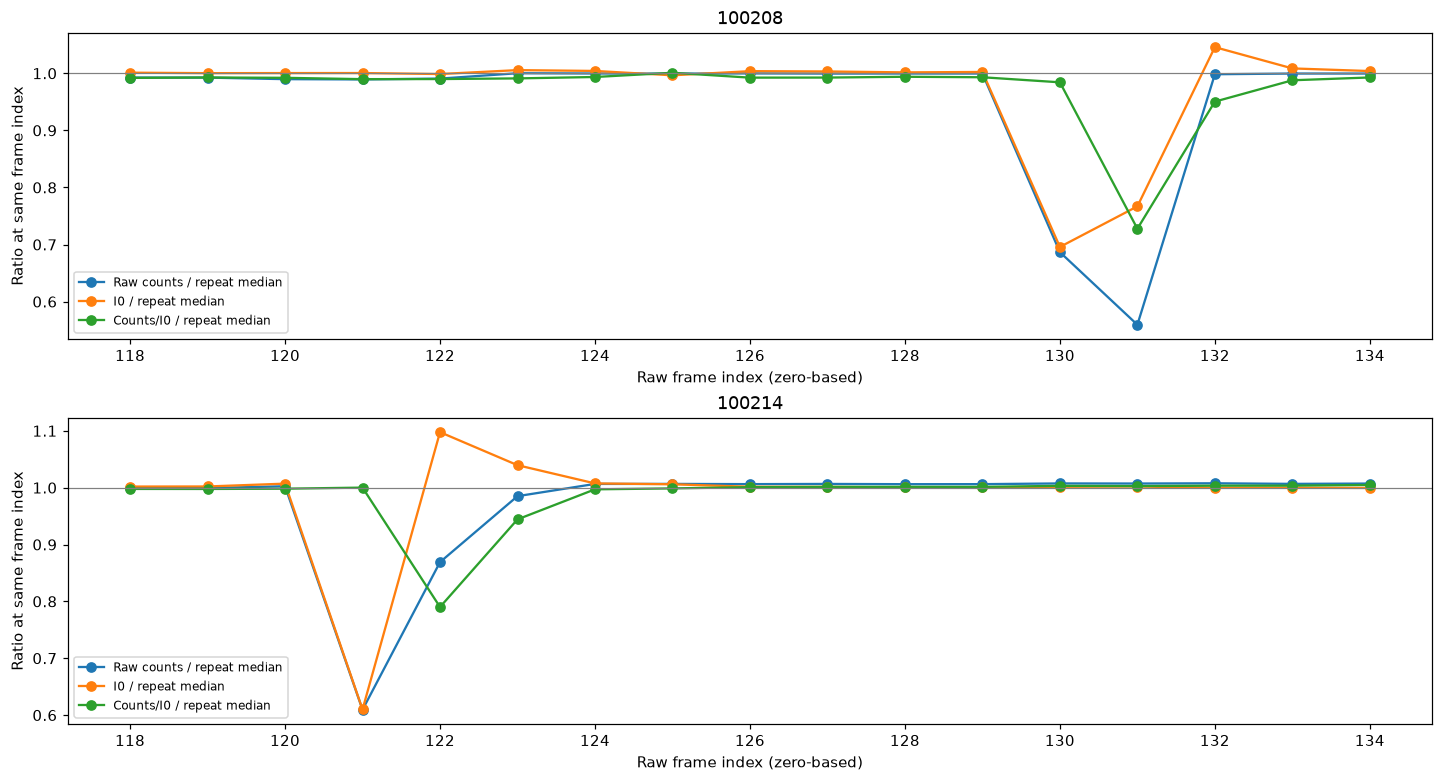

,scan,frame_index,motor_tth_deg,pixel_tth_min,pixel_tth_max
0,100208,130,52.49999,42.55596,59.85140
1,100208,131,52.49999,42.55596,59.85140
2,100208,132,52.99997,43.05265,60.34641
3,100214,121,50.00001,40.07243,57.37669
4,100214,122,50.49999,40.56913,57.87157
5,100214,123,50.49999,40.56913,57.87157


,omitted_frames,original_max_jump_log_percent,omission_max_jump_log_percent,original_p95_log_percent,omission_p95_log_percent,original_worst_boundary_deg,jump_at_original_boundary_after_omission
scan,,,,,,,
100208,"(130, 131, 132)",0.288176,0.078281,0.057645,0.040491,59.777817,0.001086
100214,"(121, 122, 123)",0.205512,0.070615,0.045920,0.039150,57.793072,0.018909


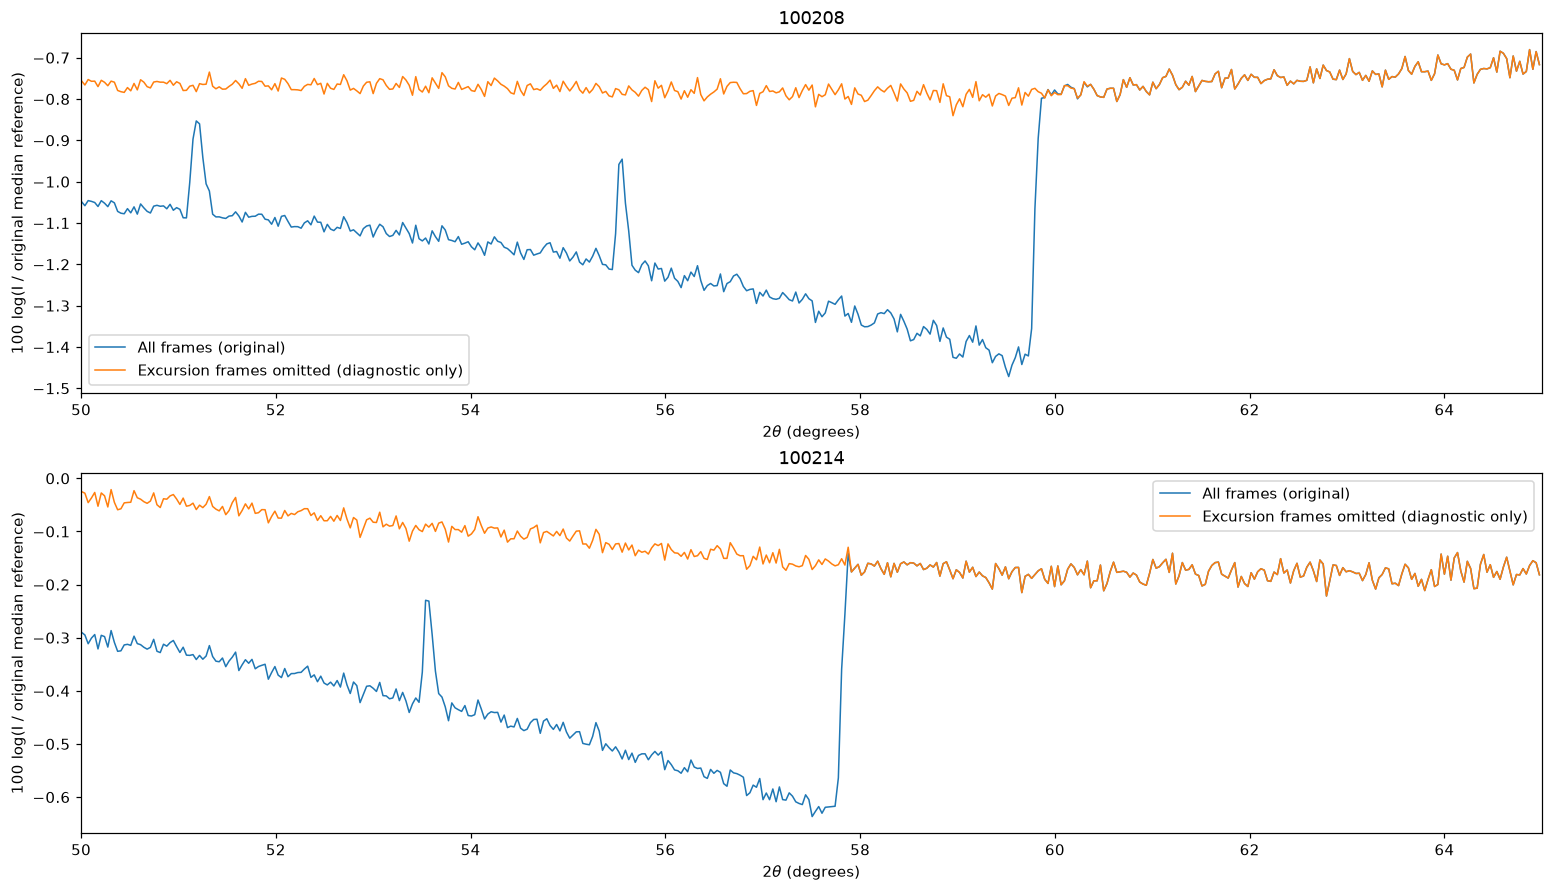

In [32]:
# Target windows fixed after inspecting the recorded I0 excursions, not tuned to minimise jump scores.
excursion_frames = {100208: (130, 131, 132), 100214: (121, 122, 123)}  # Zero-based.
inspection_indices = np.arange(118, 135)
acquisition_sums, acquisition_i0, acquisition_gains = [], [], []
for scan_number, (source_scan, calibration_path) in zip(SCANS, integration_sources):
    with h5py.File(source_scan.detector_path, 'r') as source_file:
        frame_sums = []
        for frame_index in inspection_indices:
            counts = np.asarray(source_file[source_scan.detector_dataset][int(frame_index)], dtype=float)
            valid = ~base_union & np.isfinite(counts) & (counts >= 0) & (counts < RAW_SATURATION)
            frame_sums.append(np.sum(counts, where=valid))
    acquisition_sums.append(frame_sums)
    acquisition_i0.append(source_scan.i0[inspection_indices])
    with h5py.File(calibration_path, 'r') as cal_file:
        acquisition_gains.append(cal_file['fit_diagnostics/frame_gains'][()][inspection_indices])
acquisition_sums, acquisition_i0, acquisition_gains = map(np.asarray, (acquisition_sums, acquisition_i0, acquisition_gains))
count_ratios = acquisition_sums / np.median(acquisition_sums, axis=0)
i0_ratios = acquisition_i0 / np.median(acquisition_i0, axis=0)
normalised_sums = acquisition_sums / acquisition_i0
normalised_ratios = normalised_sums / np.median(normalised_sums, axis=0)
acquisition_anomaly_rows = []
for scan_number, omitted in excursion_frames.items():
    row_index = int(np.flatnonzero(SCANS == scan_number)[0])
    source_scan = integration_sources[row_index][0]
    for frame_index in omitted:
        column = int(np.flatnonzero(inspection_indices == frame_index)[0])
        acquisition_anomaly_rows.append({'scan': scan_number, 'frame_index_zero_based': frame_index,
                                         'motor_tth_deg': source_scan.angles[frame_index],
                                         'raw_count_ratio': count_ratios[row_index, column],
                                         'i0_ratio': i0_ratios[row_index, column],
                                         'counts_over_i0_ratio': normalised_ratios[row_index, column],
                                         'saved_frame_gain': acquisition_gains[row_index, column]})
acquisition_anomalies = pd.DataFrame(acquisition_anomaly_rows)
display(acquisition_anomalies.round(6))
fig, axes = plt.subplots(2, 1, figsize=(13, 7), constrained_layout=True)
for ax, scan_number in zip(axes, excursion_frames):
    i = int(np.flatnonzero(SCANS == scan_number)[0])
    ax.plot(inspection_indices, count_ratios[i], 'o-', label='Raw counts / repeat median')
    ax.plot(inspection_indices, i0_ratios[i], 'o-', label='I0 / repeat median')
    ax.plot(inspection_indices, normalised_ratios[i], 'o-', label='Counts/I0 / repeat median')
    ax.axhline(1, color='0.5', lw=0.8)
    ax.set(title=str(scan_number), xlabel='Raw frame index (zero-based)', ylabel='Ratio at same frame index')
    ax.legend(fontsize=8)
plt.show()

# Only 2theta integrations are needed for this diagnostic, using exactly the shared helper and merge.
excursion_test_rows, excursion_test_patterns, excursion_extent_rows = [], {}, []
for scan_number, omitted in excursion_frames.items():
    i = int(np.flatnonzero(SCANS == scan_number)[0])
    source_scan, calibration_path = integration_sources[i]
    cal = workflow.load_calibration(calibration_path)
    physical_model = workflow.model_for_processing(source_scan, cal)
    mask = cal['base_mask'].astype(bool) | cal['bad_pixel_mask'].astype(bool) | source_scan.native_mask
    retained_results = {}
    with h5py.File(source_scan.detector_path, 'r') as source_file:
        for frame_index, angle in enumerate(source_scan.angles):
            if frame_index in omitted:
                ai = physical_model.geometry.get_ai(float(angle))
                theta_pixels = np.rad2deg(ai.center_array(source_scan.shape, unit='2th_rad'))
                valid = ~mask & np.isfinite(theta_pixels)
                excursion_extent_rows.append({'scan': scan_number, 'frame_index': frame_index,
                                              'motor_tth_deg': angle, 'pixel_tth_min': theta_pixels[valid].min(),
                                              'pixel_tth_max': theta_pixels[valid].max()})
                continue
            retained_results[frame_index] = workflow.integrate_frame(
                physical_model, source_file[source_scan.detector_dataset][frame_index], angle,
                source_scan.i0[frame_index], mask, cal['combined_divisor'], THETA_POINTS,
                common_theta_range, unit='2th_deg', frame_gain=cal['frame_gains'][frame_index],
                saturation=RAW_SATURATION)
    merged = workflow.merge_results(retained_results)
    np.testing.assert_allclose(merged['axis'], two_theta)
    excursion_test_patterns[scan_number] = merged
    if not np.all(np.isfinite(merged['intensity'][high_angle_support]) & (merged['intensity'][high_angle_support] > 0)):
        raise ValueError('Omitting these frames removes common high-angle support.')
    test_log_residual = np.full(THETA_POINTS, np.nan)
    support = np.isfinite(merged['intensity']) & (merged['intensity'] > 0) & common_1d
    test_log_residual[support] = 100 * np.log(merged['intensity'][support]) - reference_log_pattern[support]
    jumps = np.array([test_log_residual[j-h:j+h] @ jump_weights for j in boundary_indices])
    original_worst = int(np.argmax(np.abs(differential_jumps[i])))
    excursion_test_rows.append({'scan': scan_number, 'omitted_frames': str(omitted),
                                'original_max_jump_log_percent': np.max(np.abs(differential_jumps[i])),
                                'omission_max_jump_log_percent': np.max(np.abs(jumps)),
                                'original_p95_log_percent': np.percentile(np.abs(differential_jumps[i]), 95),
                                'omission_p95_log_percent': np.percentile(np.abs(jumps), 95),
                                'original_worst_boundary_deg': jump_angles[original_worst],
                                'jump_at_original_boundary_after_omission': jumps[original_worst]})
    del physical_model, retained_results, cal
    gc.collect()
excursion_test_summary = pd.DataFrame(excursion_test_rows).set_index('scan')
excursion_frame_extents = pd.DataFrame(excursion_extent_rows)
display(excursion_frame_extents.round(5))
display(excursion_test_summary.round(6))
fig, axes = plt.subplots(2, 1, figsize=(14, 8), constrained_layout=True)
for ax, scan_number in zip(axes, excursion_frames):
    i = int(np.flatnonzero(SCANS == scan_number)[0])
    test = excursion_test_patterns[scan_number]['intensity']
    residual = np.full(THETA_POINTS, np.nan)
    residual[high_angle_support] = 100 * np.log(test[high_angle_support]) - reference_log_pattern[high_angle_support]
    ax.plot(two_theta, np.where(high_angle_support, log_ratio_patterns[i], np.nan), label='All frames (original)', lw=1)
    ax.plot(two_theta, residual, label='Excursion frames omitted (diagnostic only)', lw=1)
    ax.set(xlim=HIGH_ANGLE_RANGE, title=str(scan_number), xlabel=r'$2\theta$ (degrees)',
           ylabel='100 log(I / original median reference)')
    ax.legend()
plt.show()

#### Follow-up findings: acquisition transients explain the standout steps

- **100208:** at raw index 131 (motor 52.5°), detector counts are about **56%** of the same-index repeat median, but I0 is about **77%**. Counts/I0 therefore remains about **27% low**. Its saved frame gain is 0.9949, so the fitted gain barely compensates this frame. Nearby indices 130 and 132 also show the drop/recovery episode.
- **100214:** at index 122 (motor 50.5°), detector counts are about **87%** of the repeat median but I0 is about **110%**, leaving counts/I0 about **21% low**. The saved frame gain is 0.9512, near the fitter's approximately 5% log-gain bound; it cannot compensate a mismatch this large. Index 121, by contrast, has matching count/I0 drops and normalises well.
- **The angular connection is specific:** the affected 52.5° frames in 100208 cover detector-pixel 2θ up to about **59.85°**, near its strongest observed jump at **59.78°**. The affected 50.5° frames in 100214 extend to about **57.87°**, near its strongest jump at **57.79°**. As the affected frames cease contributing to the merged pattern, their intensity deficit disappears, producing a step. Smaller structures can arise where their contribution changes within the detector footprint.
- **Targeted omission strongly supports that explanation:** keeping the calibration and reference unchanged but excluding only the excursion frames reduces the jump at the original worst boundary from **0.2882 to 0.0011 log-%** for 100208 and **0.2055 to 0.0189 log-%** for 100214. The maximum over the entire high-angle window drops to **0.0783** and **0.0706 log-%**, respectively; the residual plots lose the standout steps/spikes. This is diagnostic evidence, not a silently applied data-cleaning rule.

**Interpretation:** these particular 1D artefacts are primarily associated with a short **beam/intensity–monitor mismatch during acquisition**, rather than simply the monotonic increase of ridge coverage or learned bad pixels. The observations are compatible with a beam interruption/recovery combined with differing detector/monitor integration timing or response, but do **not** establish the hardware cause (for example top-up, a shutter event, or monitor timing). Accelerator/beamline event logs and exposure timestamps are needed to distinguish those possibilities. Recorded angles agree across repeats within approximately 0.000056°, arguing against a large *recorded* angle mismatch, though that does not verify actual motor motion.

100210 also has a large I0/count mismatch, but at motor angles around **34.5–35°**, outside the angular position of the anomalies considered here. It warrants a similar lower-angle check; the issue is not unique to 100208/100214. The scan-specific transient finding is distinct from, and does not invalidate, the separate detector-map prevalence trend or the need to evaluate a whole-detector reset strategy.

## Validation and optional export (off by default)

The checks verify per-scan map area accounting, fixed supports, raw/I0 normalisation, and merged 1D intensity/variance arithmetic. The discontinuity section also tests a synthetic unit step and linear slope. These are implementation checks, not scientific validation of defect identity or a reset threshold.

Set `EXPORT_RESULTS = True` in the setup to save whole-detector prevalence, raw-frame provenance, independently extracted maps, the **2000-bin integrated patterns and Poisson sigmas**, jump metrics, candidate boundaries and integration settings to a new directory inside this repository. Existing directories are refused; acquisition files are opened read-only and never modified. No sensor-number breakdowns are exported. All patterns are in-memory otherwise, so rerunning the integration cell recomputes them.

In [31]:
np.testing.assert_array_equal(repeat_summary['ridge_area_pixels'].to_numpy(), repeat_line_masks.sum(axis=(1, 2)))
np.testing.assert_allclose(repeat_summary['ridge_area_percent'],
                           repeat_summary['bright_area_percent'] + repeat_summary['dark_area_percent'])
np.testing.assert_allclose(np.diff(summary['bad_fixed_count']), new_flags[1:] - cleared_flags[1:])
for i, table in enumerate(fragment_tables):
    assert int(table['area_pixels'].sum()) == int(repeat_line_masks[i].sum())
    assert len(table) == int(repeat_labels[i].max())
    assert np.all(~repeat_line_masks[i] | ridge_support)
np.testing.assert_allclose(ridge_response(-log_maps[0])[ridge_support],
                           -repeat_responses[0, ridge_support], rtol=1e-10, atol=1e-10)
np.testing.assert_allclose(raw_normalised[:, raw_support] * raw_frame_summary['i0'].to_numpy()[:, None],
                           raw_frames[:, raw_support], rtol=1e-12, atol=1e-10)
assert np.ptp(selected_angles) <= RAW_ANGLE_TOLERANCE_DEG
assert raw_frame_summary.index.equals(prevalence.index)
assert intensity_1d.shape == sigma_1d.shape == (len(SCANS), 2000)
assert np.all(np.isfinite(differential_jumps))
print('Validation passed: map metrics, raw/I0 comparison, 2000-point patterns and finite discontinuity metrics.')

if EXPORT_RESULTS:
    destination = EXPORT_DIRECTORY.resolve()
    if not destination.is_relative_to(ROOT.resolve()) or destination.is_relative_to(RAW_DIRECTORY.resolve()):
        raise ValueError('Export must stay inside the repository, outside the acquisition directory.')
    destination.mkdir(parents=True, exist_ok=False)
    combined_metrics.to_csv(destination / 'prevalence_and_discontinuities_by_scan.csv')
    integration_summary.to_csv(destination / 'integration_summary.csv')
    discontinuity_candidates.to_csv(destination / 'discontinuity_candidates.csv', index=False)
    strongest_jumps.to_csv(destination / 'strongest_jump_by_scan.csv')
    association_summary.to_csv(destination / 'descriptive_associations.csv')
    metric_sensitivity.to_csv(destination / 'jump_scale_sensitivity.csv')
    raw_frame_summary.to_csv(destination / 'raw_frame_provenance.csv')
    bad_pixels.to_csv(destination / 'bad_pixel_candidates.csv', index=False)
    fragments.to_csv(destination / 'ridge_fragments_by_scan.csv', index=False)
    with h5py.File(destination / 'analysis_maps.h5', 'x') as output:
        output.attrs['purpose'] = 'Whole-detector prevalence and own-corrected 1D analysis; not replacement calibration'
        output.attrs['uncertainty'] = workflow.UNCERTAINTY
        for name, array in {'scans': SCANS, 'bad_pixel_support': bad_support,
                            'bad_flags_by_scan': fixed_bad, 'ridge_support': ridge_support,
                            'ridge_response_by_scan': repeat_responses,
                            'fragment_labels_by_scan': repeat_labels,
                            'raw_frame_support': raw_support,
                            'raw_counts_over_i0_by_scan': raw_normalised,
                            'two_theta_deg': two_theta, 'intensity_1d': intensity_1d,
                            'poisson_sigma_1d': sigma_1d,
                            'integration_accumulators': np.stack([p['accumulators'] for p in patterns_1d]),
                            'within_fit_q_range': np.stack([p['within_fit_range'] for p in patterns_1d]),
                            'high_angle_support': high_angle_support,
                            'reference_log_pattern': reference_log_pattern,
                            'jump_boundary_two_theta_deg': jump_angles,
                            'differential_jumps_log_percent': differential_jumps}.items():
            output.create_dataset(name, data=array, compression='gzip')
        output['integration_accumulators'].attrs['field_order'] = 'sum_signal,sum_normalization,sum_variance,count'
    for i, scan_number in enumerate(SCANS):
        np.savetxt(destination / f'{scan_number}_own_correction_2000.xy',
                   np.column_stack((two_theta[common_1d], intensity_1d[i, common_1d], sigma_1d[i, common_1d])),
                   header='two_theta_deg intensity poisson_sigma; own-source frame gains applied')
    provenance = {'inputs': [str(path.relative_to(ROOT)) for path in paths],
                  'input_sha256': {path.name: hashlib.sha256(path.read_bytes()).hexdigest() for path in paths},
                  'ridge_sigma': RIDGE_SIGMA, 'ridge_beta': RIDGE_BETA, 'ridge_threshold': RIDGE_THRESHOLD,
                  'minimum_fragment_area': MIN_LINE_PIXELS, 'gaussian_truncate': TRUNCATE,
                  'bad_pixel_support_pixels': int(bad_support.sum()),
                  'ridge_support_pixels': int(ridge_support.sum()),
                  'raw_frame_index_zero_based': raw_frame_index,
                  'raw_normalisation': 'Raw counts divided by exact frame I0; no learned correction in raw figures',
                  'raw_saturation': RAW_SATURATION,
                  'raw_angle_tolerance_deg': RAW_ANGLE_TOLERANCE_DEG,
                  'raw_full_display_limits': [float(raw_vmin), float(raw_vmax)],
                  'raw_zoom_display_limits': [float(roi_vmin), float(roi_vmax)],
                  'raw_zoom_row_column_bounds': [[axis.start, axis.stop] for axis in RAW_ZOOM],
                  'theta_bins': THETA_POINTS, 'theta_range_deg': common_theta_range,
                  'high_angle_range_deg': HIGH_ANGLE_RANGE, 'step_half_window_bins': STEP_HALF_WINDOW,
                  'step_candidate_threshold_log_percent': STEP_CANDIDATE_PERCENT,
                  'source_frame_gains_applied': True, 'allow_divisor_extrapolation': True,
                  'discontinuity_reference': 'Binwise median log intensity of these ten own-corrected scans',
                  'method': 'workflow.process_scan / merge_results; independent per-scan map extraction',
                  'fit_settings': [json.loads(value) for value in summary['fit_settings']],
                  'versions': {'numpy': np.__version__, 'pandas': pd.__version__, 'h5py': h5py.__version__,
                               'pyfai': workflow.pyFAI.version}}
    (destination / 'provenance.json').write_text(json.dumps(provenance, indent=2) + '\n')
    print(f'Exported analysis products to {destination}')
else:
    print('Export disabled; acquisition files and source corrections unchanged.')

Validation passed: map metrics, raw/I0 comparison, 2000-point patterns and finite discontinuity metrics.
Export disabled; acquisition files and source corrections unchanged.
